<a href="https://colab.research.google.com/github/dashabhipsa/Projects/blob/main/Explainable_%26_Uncertainty_Aware_Breast_Ultrasound_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA


In [1]:
import pandas as pd

df = pd.read_parquet(
    "hf://datasets/SamIndia/BUSI/data/train-00000-of-00001.parquet"
)

In [2]:
print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(df["class_label"].value_counts())

print("\nClass percentages:")
print(df["class_label"].value_counts(normalize=True) * 100)

print("\nMultifocal lesion distribution:")
print(df["has_multifocal_lesion"].value_counts())

print("\nUnique image IDs:", df["image_id"].nunique())

Dataset shape: (780, 5)

Class distribution:
class_label
benign       437
malignant    210
normal       133
Name: count, dtype: int64

Class percentages:
class_label
benign       56.025641
malignant    26.923077
normal       17.051282
Name: proportion, dtype: float64

Multifocal lesion distribution:
has_multifocal_lesion
False    763
True      17
Name: count, dtype: int64

Unique image IDs: 780


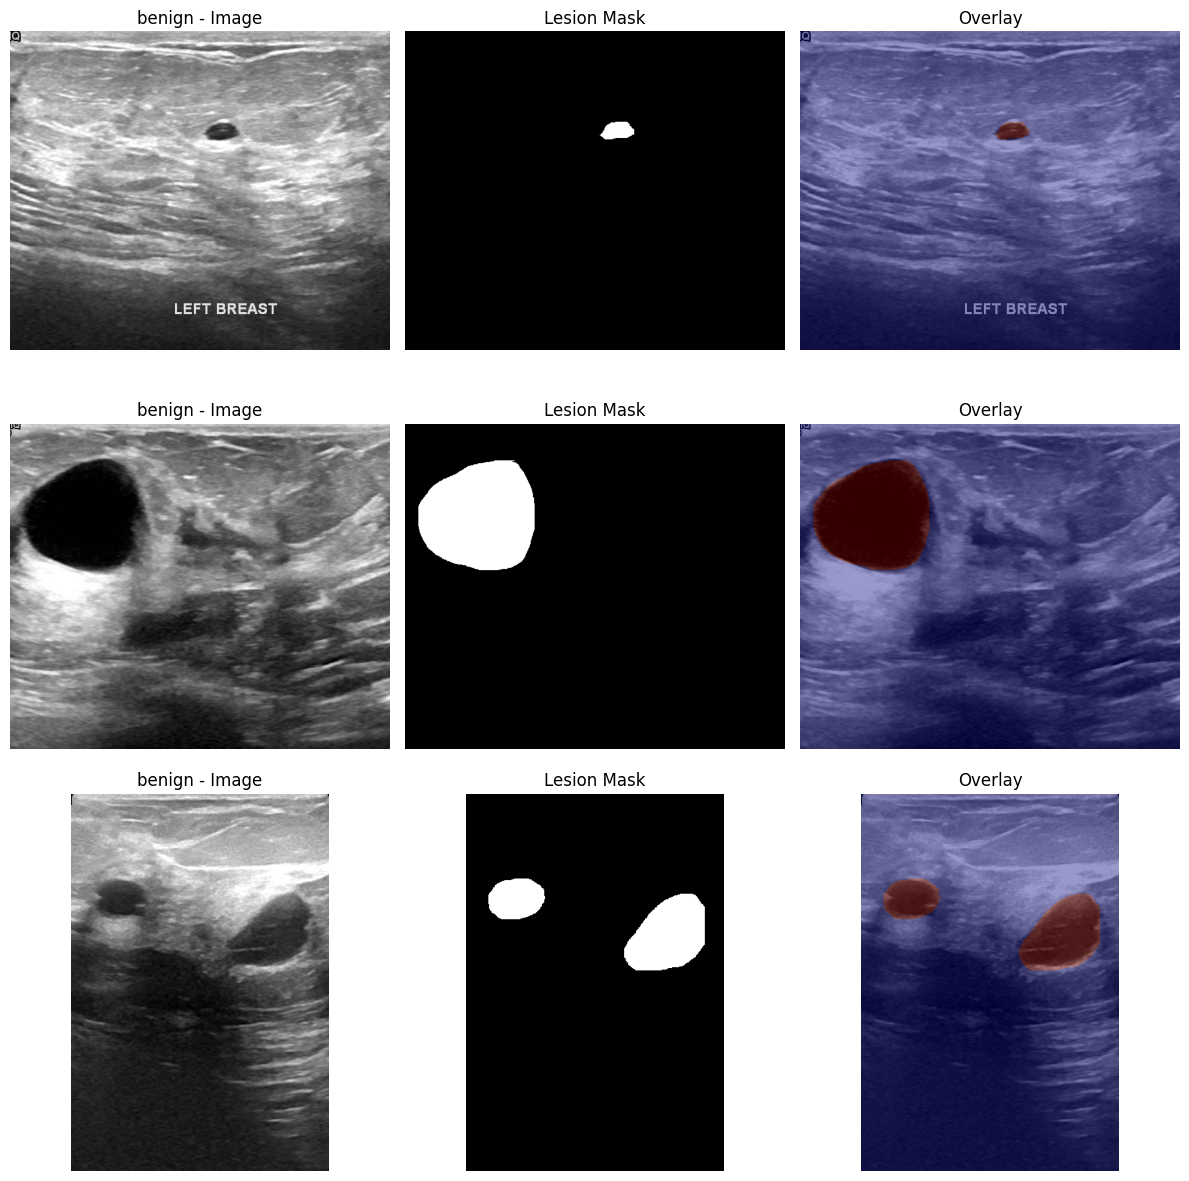

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i in range(3):
    row = df.iloc[i]

    image = Image.open(BytesIO(row["image"]["bytes"]))
    mask = Image.open(BytesIO(row["mask"]["bytes"]))

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(f'{row["class_label"]} - Image')

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Lesion Mask")

    axes[i, 2].imshow(image, cmap="gray")
    axes[i, 2].imshow(mask, cmap="jet", alpha=0.4)
    axes[i, 2].set_title("Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
from PIL import Image
from io import BytesIO

dimensions = []

for _, row in df.iterrows():
    img = Image.open(BytesIO(row["image"]["bytes"]))
    mask = Image.open(BytesIO(row["mask"]["bytes"]))

    dimensions.append({
        "image_width": img.width,
        "image_height": img.height,
        "mask_width": mask.width,
        "mask_height": mask.height
    })

dimensions_df = pd.DataFrame(dimensions)

display(dimensions_df.describe())
print("\nUnique image dimensions:")
print(dimensions_df.value_counts().head(10))

,image_width,image_height,mask_width,mask_height
count,780.000000,780.000000,780.000000,780.000000
mean,615.679487,501.452564,615.679487,501.452564
std,122.055701,76.687948,122.055701,76.687948
min,190.000000,310.000000,190.000000,310.000000
25%,554.000000,465.000000,554.000000,465.000000
50%,564.000000,474.000000,564.000000,474.000000
75%,713.500000,574.000000,713.500000,574.000000
max,1048.000000,719.000000,1048.000000,719.000000



Unique image dimensions:
image_width  image_height  mask_width  mask_height
557          465           557         465            6
562          470           562         470            5
564          469           564         469            4
772          574           772         574            4
560          468           560         468            4
558          467           558         467            4
556          467           556         467            4
775          587           775         587            4
557          471           557         471            4
469          394           469         394            3
Name: count, dtype: int64


In [5]:
import numpy as np

mask_areas = []

for _, row in df.iterrows():
    mask = np.array(
        Image.open(BytesIO(row["mask"]["bytes"])).convert("L")
    )

    binary_mask = mask > 0

    coverage = binary_mask.sum() / binary_mask.size

    mask_areas.append(coverage)

df["mask_coverage"] = mask_areas

display(
    df.groupby("class_label")["mask_coverage"].describe()
)

,count,mean,std,min,25%,50%,75%,max
class_label,,,,,,,,
benign,437.0,0.068846,0.083382,0.002812,0.015109,0.037902,0.091286,0.512973
malignant,210.0,0.147437,0.107059,0.005060,0.060462,0.120606,0.206592,0.562924
normal,133.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [6]:
import hashlib
from sklearn.model_selection import train_test_split

df = df.copy()

df["image_hash"] = df["image"].apply(
    lambda x: hashlib.sha256(x["bytes"]).hexdigest()
)

print("Duplicate image files:", df["image_hash"].duplicated().sum())

print("\nClass distribution:")
print(df["class_label"].value_counts())

# 70% train, 15% validation, 15% test
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class_label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_label"],
    random_state=42
)

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nClass distribution per split:")

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print(split["class_label"].value_counts())

Duplicate image files: 1

Class distribution:
class_label
benign       437
malignant    210
normal       133
Name: count, dtype: int64

Split sizes:
Train: 546
Validation: 117
Test: 117

Class distribution per split:

Train
class_label
benign       306
malignant    147
normal        93
Name: count, dtype: int64

Validation
class_label
benign       65
malignant    32
normal       20
Name: count, dtype: int64

Test
class_label
benign       66
malignant    31
normal       20
Name: count, dtype: int64


benign (433) | Label: benign | Mask coverage: 0.012538370720188902
malignant (145) | Label: malignant | Mask coverage: 0.016182605273514363


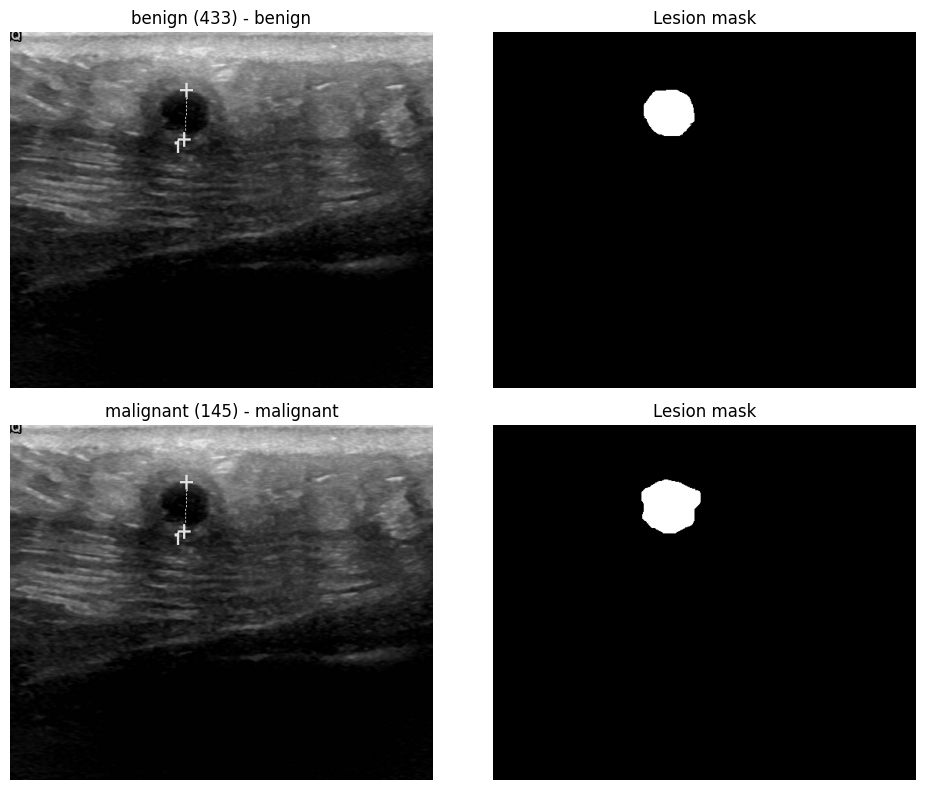

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
import numpy as np

# Identify duplicate images using their hashes
duplicates = df[df["image_hash"].duplicated(keep=False)]

# Setup the plot based on the number of duplicates found
num_duplicates = len(duplicates)
if num_duplicates > 0:
    fig, axes = plt.subplots(num_duplicates, 2, figsize=(10, 4 * num_duplicates))

    # Ensure axes is a 2D array even if there is only 1 duplicate pair
    if num_duplicates == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, (_, row) in enumerate(duplicates.iterrows()):
        image = Image.open(
            BytesIO(row["image"]["bytes"])
        ).convert("RGB")

        mask = Image.open(
            BytesIO(row["mask"]["bytes"])
        ).convert("L")

        axes[i, 0].imshow(image)
        axes[i, 0].set_title(
            f'{row["image_id"]} - {row["class_label"]}'
        )

        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Lesion mask")

        print(
            row["image_id"],
            "| Label:", row["class_label"],
            "| Mask coverage:",
            (np.array(mask) > 0).mean()
        )

    for ax in axes.flat:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No duplicate images found in the dataset.")

In [8]:
conflicting_hashes = (
    df.groupby("image_hash")["class_label"]
    .nunique()
)

conflicting_hashes = conflicting_hashes[
    conflicting_hashes > 1
].index

df_clean = df[
    ~df["image_hash"].isin(conflicting_hashes)
].copy().reset_index(drop=True)

print("Original samples:", len(df))
print("Clean samples:", len(df_clean))

print("\nUpdated class distribution:")
print(df_clean["class_label"].value_counts())

Original samples: 780
Clean samples: 778

Updated class distribution:
class_label
benign       436
malignant    209
normal       133
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    stratify=df_clean["class_label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_label"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print(split["class_label"].value_counts())

Train: 544
Validation: 117
Test: 117

Train
class_label
benign       305
malignant    146
normal        93
Name: count, dtype: int64

Validation
class_label
benign       65
malignant    32
normal       20
Name: count, dtype: int64

Test
class_label
benign       66
malignant    31
normal       20
Name: count, dtype: int64


In [10]:
import numpy as np
import torch
from PIL import Image, ImageOps
from io import BytesIO
from torch.utils.data import Dataset
from torchvision import transforms

IMG_SIZE = 224

class BUSIDataset(Dataset):
    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

        self.label_map = {
            "benign": 0,
            "malignant": 1,
            "normal": 2
        }

        self.image_transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = Image.open(
            BytesIO(row["image"]["bytes"])
        ).convert("RGB")

        mask = Image.open(
            BytesIO(row["mask"]["bytes"])
        ).convert("L")

        image = ImageOps.pad(
            image, (IMG_SIZE, IMG_SIZE),
            method=Image.Resampling.BILINEAR
        )

        mask = ImageOps.pad(
            mask, (IMG_SIZE, IMG_SIZE),
            method=Image.Resampling.NEAREST
        )

        image = self.image_transform(image)

        mask = torch.from_numpy(
            (np.array(mask) > 0).astype(np.float32)
        ).unsqueeze(0)

        label = self.label_map[row["class_label"]]

        return image, mask, torch.tensor(label, dtype=torch.long)

# EfficientNet-B0 baseline

In [11]:
import os
import random
import copy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import BytesIO
from PIL import Image, ImageOps

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 40
PATIENCE = 8
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

CLASSES = ["benign", "malignant", "normal"]
NUM_CLASSES = len(CLASSES)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [12]:
class BUSIDataset(Dataset):

    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment

        self.label_map = {
            "benign": 0,
            "malignant": 1,
            "normal": 2
        }

        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

        self.color_jitter = transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10
        )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        image = Image.open(
            BytesIO(row["image"]["bytes"])
        ).convert("RGB")

        mask = Image.open(
            BytesIO(row["mask"]["bytes"])
        ).convert("L")

        image = ImageOps.pad(
            image,
            (IMG_SIZE, IMG_SIZE),
            method=Image.Resampling.BILINEAR
        )

        mask = ImageOps.pad(
            mask,
            (IMG_SIZE, IMG_SIZE),
            method=Image.Resampling.NEAREST
        )

        if self.augment:

            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            if random.random() < 0.5:
                angle = random.uniform(-10, 10)

                image = TF.rotate(
                    image,
                    angle,
                    interpolation=InterpolationMode.BILINEAR,
                    fill=0
                )

                mask = TF.rotate(
                    mask,
                    angle,
                    interpolation=InterpolationMode.NEAREST,
                    fill=0
                )

            image = self.color_jitter(image)

        image = TF.to_tensor(image)
        image = self.normalize(image)

        mask = torch.from_numpy(
            (np.array(mask) > 0).astype(np.float32)
        ).unsqueeze(0)

        label = self.label_map[row["class_label"]]

        return (
            image,
            mask,
            torch.tensor(label, dtype=torch.long)
        )

In [13]:
train_dataset = BUSIDataset(train_df, augment=True)
val_dataset = BUSIDataset(val_df, augment=False)
test_dataset = BUSIDataset(test_df, augment=False)

PIN_MEMORY = DEVICE.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

images, masks, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Labels:", labels.shape)

Images: torch.Size([16, 3, 224, 224])
Masks: torch.Size([16, 1, 224, 224])
Labels: torch.Size([16])


In [14]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["class_label"].map({
        "benign": 0,
        "malignant": 1,
        "normal": 2
    }).values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("Class weights:")
for name, weight in zip(CLASSES, class_weights):
    print(f"{name}: {weight.item():.4f}")

Class weights:
benign: 0.5945
malignant: 1.2420
normal: 1.9498


In [15]:
weights = models.EfficientNet_B0_Weights.DEFAULT

model = models.efficientnet_b0(weights=weights)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

print("Model: EfficientNet-B0")
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 186MB/s]

Model: EfficientNet-B0
Trainable parameters: 4011391


In [16]:
def run_epoch(model, loader, optimizer=None):

    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0
    all_labels = []
    all_preds = []
    all_probs = []

    for images, _, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=DEVICE.type == "cuda"
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        probs = torch.softmax(outputs.float(), dim=1)
        preds = probs.argmax(dim=1)

        total_loss += loss.item() * labels.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(all_labels, all_preds)

    return {
        "loss": avg_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "labels": np.array(all_labels),
        "predictions": np.array(all_preds),
        "probabilities": np.array(all_probs)
    }

In [17]:
OUTPUT_DIR = "/content/BUSI_Experiment_1"
os.makedirs(OUTPUT_DIR, exist_ok=True)

best_f1 = -1
best_epoch = 0
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    train_metrics = run_epoch(
        model,
        train_loader,
        optimizer
    )

    val_metrics = run_epoch(
        model,
        val_loader
    )

    scheduler.step(val_metrics["macro_f1"])

    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["train_f1"].append(train_metrics["macro_f1"])
    history["val_f1"].append(val_metrics["macro_f1"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_accuracy"].append(val_metrics["accuracy"])

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Train F1: {train_metrics['macro_f1']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_f1:

        best_f1 = val_metrics["macro_f1"]
        best_epoch = epoch + 1
        patience_counter = 0

        checkpoint = {
            "epoch": best_epoch,
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_f1": best_f1,
            "val_metrics": {
                "loss": val_metrics["loss"],
                "accuracy": val_metrics["accuracy"],
                "macro_f1": val_metrics["macro_f1"]
            },
            "classes": CLASSES,
            "seed": SEED,
            "config": {
                "img_size": IMG_SIZE,
                "batch_size": BATCH_SIZE,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "model": "EfficientNet-B0"
            },
            "train_ids": train_df["image_id"].tolist(),
            "val_ids": val_df["image_id"].tolist(),
            "test_ids": test_df["image_id"].tolist(),
            "history": history
        }

        torch.save(
            checkpoint,
            os.path.join(OUTPUT_DIR, "best_model.pth")
        )

        print("  Best model saved.")

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation macro F1:", round(best_f1, 4))

Epoch 01/40 | Train Loss: 1.0357 | Val Loss: 0.9351 | Train F1: 0.4713 | Val F1: 0.5938
  Best model saved.
Epoch 02/40 | Train Loss: 0.7768 | Val Loss: 0.5788 | Train F1: 0.6976 | Val F1: 0.7580
  Best model saved.
Epoch 03/40 | Train Loss: 0.5177 | Val Loss: 0.4426 | Train F1: 0.7740 | Val F1: 0.8044
  Best model saved.
Epoch 04/40 | Train Loss: 0.4023 | Val Loss: 0.3728 | Train F1: 0.7891 | Val F1: 0.8268
  Best model saved.
Epoch 05/40 | Train Loss: 0.3326 | Val Loss: 0.3595 | Train F1: 0.8386 | Val F1: 0.8212
Epoch 06/40 | Train Loss: 0.2137 | Val Loss: 0.3355 | Train F1: 0.9259 | Val F1: 0.8208
Epoch 07/40 | Train Loss: 0.1970 | Val Loss: 0.3250 | Train F1: 0.8976 | Val F1: 0.8485
  Best model saved.
Epoch 08/40 | Train Loss: 0.1794 | Val Loss: 0.3629 | Train F1: 0.9247 | Val F1: 0.8234
Epoch 09/40 | Train Loss: 0.1626 | Val Loss: 0.3196 | Train F1: 0.9346 | Val F1: 0.8315
Epoch 10/40 | Train Loss: 0.1254 | Val Loss: 0.3470 | Train F1: 0.9504 | Val F1: 0.8540
  Best model saved.


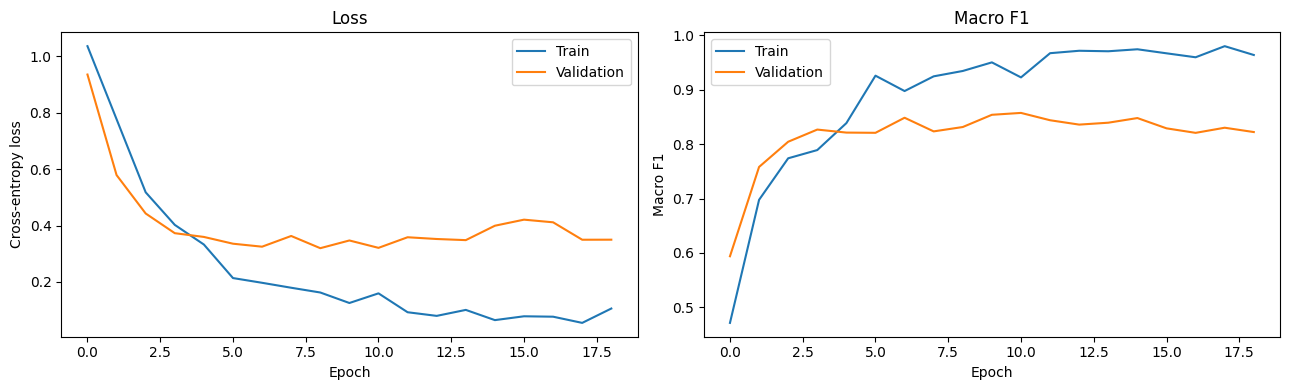

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(history["train_f1"], label="Train")
axes[1].plot(history["val_f1"], label="Validation")
axes[1].set_title("Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "training_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [19]:
checkpoint_path = os.path.join(
    OUTPUT_DIR, "best_model.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_metrics = run_epoch(model, test_loader)

y_true = test_metrics["labels"]
y_pred = test_metrics["predictions"]
y_prob = test_metrics["probabilities"]

test_accuracy = accuracy_score(y_true, y_pred)

test_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

test_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="macro"
)

print("BEST CHECKPOINT")
print("Best epoch:", checkpoint["epoch"])
print("Validation macro F1:", checkpoint["best_val_f1"])

print("\nTEST RESULTS")
print(f"Accuracy:   {test_accuracy:.4f}")
print(f"Macro F1:   {test_macro_f1:.4f}")
print(f"Macro AUC:  {test_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

BEST CHECKPOINT
Best epoch: 11
Validation macro F1: 0.8574233310895418

TEST RESULTS
Accuracy:   0.8974
Macro F1:   0.8922
Macro AUC:  0.9650

Classification Report:
              precision    recall  f1-score   support

      benign     0.9355    0.8788    0.9062        66
   malignant     0.8529    0.9355    0.8923        31
      normal     0.8571    0.9000    0.8780        20

    accuracy                         0.8974       117
   macro avg     0.8819    0.9048    0.8922       117
weighted avg     0.9002    0.8974    0.8977       117



In [20]:
results = {
    "model": "EfficientNet-B0",
    "best_epoch": checkpoint["epoch"],
    "validation_macro_f1": checkpoint["best_val_f1"],
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "test_macro_auc": test_auc
}

results_df = pd.DataFrame([results])

display(results_df)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "test_results.csv"),
    index=False
)

pd.DataFrame(history).to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False
)

np.savez_compressed(
    os.path.join(OUTPUT_DIR, "test_predictions.npz"),
    y_true=y_true,
    y_pred=y_pred,
    y_prob=y_prob
)

print("Results saved:", OUTPUT_DIR)

,model,best_epoch,validation_macro_f1,test_accuracy,test_macro_f1,test_macro_auc
0,EfficientNet-B0,11,0.857423,0.897436,0.892202,0.964955


Results saved: /content/BUSI_Experiment_1


In [21]:
import os
import json
import platform
import torchvision
import sklearn
from sklearn.metrics import confusion_matrix

checkpoint_path = os.path.join(
    OUTPUT_DIR, "best_model.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

# Complete experiment configuration
checkpoint["experiment_config"] = {
    "experiment": "BUSI EfficientNet-B0 Baseline",
    "architecture": "torchvision.models.efficientnet_b0",
    "pretrained_weights": "EfficientNet_B0_Weights.DEFAULT",
    "num_classes": NUM_CLASSES,
    "classes": CLASSES,
    "class_mapping": {
        "benign": 0,
        "malignant": 1,
        "normal": 2
    },
    "image_size": IMG_SIZE,
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "augmentation": {
        "horizontal_flip_probability": 0.5,
        "rotation_range_degrees": [-10, 10],
        "brightness": 0.10,
        "contrast": 0.10
    },
    "loss": "Weighted CrossEntropyLoss",
    "class_weights": class_weights.cpu().tolist(),
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "max",
    "batch_size": BATCH_SIZE,
    "max_epochs": EPOCHS,
    "early_stopping_patience": PATIENCE,
    "seed": SEED,
    "selection_metric": "Validation Macro F1"
}

# Compute confusion matrix before storing
cm = confusion_matrix(y_true, y_pred)

# Store final test metrics
checkpoint["test_metrics"] = {
    "accuracy": float(test_accuracy),
    "macro_f1": float(test_macro_f1),
    "macro_auc": float(test_auc),
    "classification_report": classification_report(
        y_true,
        y_pred,
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    ),
    "confusion_matrix": cm.tolist()
}

# Store dataset information
checkpoint["dataset_metadata"] = {
    "dataset": "SamIndia/BUSI",
    "original_samples": 780,
    "clean_samples": len(df_clean),
    "excluded_conflicting_records": 2,
    "train_samples": len(train_df),
    "validation_samples": len(val_df),
    "test_samples": len(test_df),
    "split_strategy": "Stratified 70/15/15 image-level split",
    "split_random_state": 42,
    "duplicate_handling": "Both records with conflicting labels excluded"
}

# Software environment
checkpoint["software_versions"] = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__
}

checkpoint["rng_states"] = {
    "python": random.getstate(),
    "numpy": np.random.get_state(),
    "torch": torch.get_rng_state(),
    "cuda": torch.cuda.get_rng_state_all()
        if torch.cuda.is_available() else None
}

torch.save(checkpoint, checkpoint_path)

print("Enhanced checkpoint saved!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation F1:", checkpoint["best_val_f1"])
print("Test macro F1:", checkpoint["test_metrics"]["macro_f1"])

Enhanced checkpoint saved!
Best epoch: 11
Best validation F1: 0.8574233310895418
Test macro F1: 0.892202157598499


# Multi-task learning with lesion supervision

In [22]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

SEED = 42
BATCH_SIZE = 16
EPOCHS = 40
PATIENCE = 8
LR = 1e-4
WEIGHT_DECAY = 1e-4
LAMBDA_SEG = 0.3

set_seed(SEED)

E2_DIR = "/content/BUSI_Experiment_2"
os.makedirs(E2_DIR, exist_ok=True)

print("Device:", DEVICE)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Device: cuda
Training samples: 544
Validation samples: 117
Test samples: 117


In [23]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class LesionGuidedEfficientNet(nn.Module):

    def __init__(self, num_classes=3):
        super().__init__()

        base = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        self.encoder = base.features
        self.pool = base.avgpool

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(1280, num_classes)
        )

        self.decoder = nn.Sequential(
            ConvBlock(1280, 256),
            ConvBlock(256, 128),
            ConvBlock(128, 64),
            ConvBlock(64, 32),
            nn.Conv2d(32, 1, kernel_size=1)
        )

    def forward(self, x):

        features = self.encoder(x)

        pooled = self.pool(features)
        pooled = torch.flatten(pooled, 1)

        class_logits = self.classifier(pooled)

        seg_features = features

        for layer in self.decoder[:-1]:
            seg_features = layer(seg_features)
            seg_features = F.interpolate(
                seg_features,
                scale_factor=2,
                mode="bilinear",
                align_corners=False
            )

        seg_logits = self.decoder[-1](seg_features)

        # Interpolate the final logits up to match the input image size (224x224)
        seg_logits = F.interpolate(
            seg_logits,
            scale_factor=2,
            mode="bilinear",
            align_corners=False
        )

        return class_logits, seg_logits


model_e2 = LesionGuidedEfficientNet(
    num_classes=NUM_CLASSES
).to(DEVICE)

print("Model created successfully.")

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model_e2.parameters()
        if p.requires_grad
    )
)

x = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)

with torch.no_grad():
    class_out, seg_out = model_e2(x)

print("Classification output:", class_out.shape)
print("Segmentation output:", seg_out.shape)

del x, class_out, seg_out

Model created successfully.
Trainable parameters: 7348576
Classification output: torch.Size([2, 3])
Segmentation output: torch.Size([2, 1, 224, 224])


In [24]:
class MultiTaskLoss(nn.Module):

    def __init__(self, class_weights, lambda_seg=0.3):
        super().__init__()

        self.classification_loss = nn.CrossEntropyLoss(
            weight=class_weights
        )

        self.lambda_seg = lambda_seg

    def forward(self, class_logits, seg_logits, labels, masks):

        cls_loss = self.classification_loss(
            class_logits,
            labels
        )

        bce_loss = F.binary_cross_entropy_with_logits(
            seg_logits,
            masks
        )

        probs = torch.sigmoid(seg_logits)

        intersection = (probs * masks).sum(dim=(1, 2, 3))

        denominator = (
            probs.sum(dim=(1, 2, 3))
            + masks.sum(dim=(1, 2, 3))
        )

        dice = (
            2 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )

        dice_loss = 1 - dice.mean()

        seg_loss = 0.5 * bce_loss + 0.5 * dice_loss

        total_loss = cls_loss + self.lambda_seg * seg_loss

        return total_loss, cls_loss, seg_loss


criterion_e2 = MultiTaskLoss(
    class_weights=class_weights,
    lambda_seg=LAMBDA_SEG
).to(DEVICE)

optimizer_e2 = torch.optim.AdamW(
    model_e2.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler_e2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_e2,
    mode="max",
    factor=0.5,
    patience=3
)

scaler_e2 = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

In [25]:
def run_epoch_e2(model, loader, optimizer=None):

    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0
    total_cls_loss = 0
    total_seg_loss = 0

    all_labels = []
    all_preds = []
    all_probs = []

    dice_scores = []

    for images, masks, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=DEVICE.type == "cuda"
            ):

                class_logits, seg_logits = model(images)

                loss, cls_loss, seg_loss = criterion_e2(
                    class_logits,
                    seg_logits,
                    labels,
                    masks
                )

            if training:
                scaler_e2.scale(loss).backward()
                scaler_e2.step(optimizer)
                scaler_e2.update()

        probs = torch.softmax(class_logits.float(), dim=1)
        preds = probs.argmax(dim=1)

        seg_probs = torch.sigmoid(seg_logits.float())

        intersection = (
            seg_probs * masks
        ).sum(dim=(1, 2, 3))

        denominator = (
            seg_probs.sum(dim=(1, 2, 3))
            + masks.sum(dim=(1, 2, 3))
        )

        dice = (
            2 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_cls_loss += cls_loss.item() * batch_size
        total_seg_loss += seg_loss.item() * batch_size

        dice_scores.extend(dice.detach().cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "cls_loss": total_cls_loss / len(loader.dataset),
        "seg_loss": total_seg_loss / len(loader.dataset),
        "macro_f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ),
        "accuracy": accuracy_score(all_labels, all_preds),
        "dice": float(np.mean(dice_scores)),
        "labels": np.array(all_labels),
        "predictions": np.array(all_preds),
        "probabilities": np.array(all_probs)
    }

In [26]:
history_e2 = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
    "train_cls_loss": [],
    "val_cls_loss": [],
    "train_seg_loss": [],
    "val_seg_loss": [],
    "train_dice": [],
    "val_dice": []
}

best_f1_e2 = -1
best_epoch_e2 = 0
patience_counter_e2 = 0

for epoch in range(EPOCHS):

    train_metrics = run_epoch_e2(
        model_e2,
        train_loader,
        optimizer_e2
    )

    val_metrics = run_epoch_e2(
        model_e2,
        val_loader
    )

    scheduler_e2.step(val_metrics["macro_f1"])

    for key, metric in [
        ("train_loss", train_metrics["loss"]),
        ("val_loss", val_metrics["loss"]),
        ("train_f1", train_metrics["macro_f1"]),
        ("val_f1", val_metrics["macro_f1"]),
        ("train_cls_loss", train_metrics["cls_loss"]),
        ("val_cls_loss", val_metrics["cls_loss"]),
        ("train_seg_loss", train_metrics["seg_loss"]),
        ("val_seg_loss", val_metrics["seg_loss"]),
        ("train_dice", train_metrics["dice"]),
        ("val_dice", val_metrics["dice"])
    ]:
        history_e2[key].append(metric)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Train F1: {train_metrics['macro_f1']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"Val Dice: {val_metrics['dice']:.4f}"
    )

    if val_metrics["macro_f1"] > best_f1_e2:

        best_f1_e2 = val_metrics["macro_f1"]
        best_epoch_e2 = epoch + 1
        patience_counter_e2 = 0

        checkpoint_e2 = {
            "epoch": best_epoch_e2,
            "model_state_dict": copy.deepcopy(model_e2.state_dict()),
            "optimizer_state_dict": copy.deepcopy(optimizer_e2.state_dict()),
            "scheduler_state_dict": copy.deepcopy(scheduler_e2.state_dict()),
            "scaler_state_dict": copy.deepcopy(scaler_e2.state_dict()),
            "best_val_f1": best_f1_e2,
            "val_metrics": {
                "loss": val_metrics["loss"],
                "macro_f1": val_metrics["macro_f1"],
                "accuracy": val_metrics["accuracy"],
                "segmentation_dice": val_metrics["dice"]
            },
            "classes": CLASSES,
            "seed": SEED,
            "config": {
                "model": "LesionGuidedEfficientNet",
                "backbone": "EfficientNet-B0",
                "image_size": IMG_SIZE,
                "batch_size": BATCH_SIZE,
                "learning_rate": LR,
                "weight_decay": WEIGHT_DECAY,
                "lambda_seg": LAMBDA_SEG,
                "loss": "Weighted CE + 0.3 * (0.5 BCE + 0.5 Dice)"
            },
            "class_weights": class_weights.cpu(),
            "train_ids": train_df["image_id"].tolist(),
            "val_ids": val_df["image_id"].tolist(),
            "test_ids": test_df["image_id"].tolist(),
            "history": copy.deepcopy(history_e2)
        }

        torch.save(
            checkpoint_e2,
            os.path.join(E2_DIR, "best_model_e2.pth")
        )

        print("  Best E2 checkpoint saved.")

    else:
        patience_counter_e2 += 1

    if patience_counter_e2 >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nE2 training completed.")
print("Best epoch:", best_epoch_e2)
print("Best validation macro F1:", round(best_f1_e2, 4))

Epoch 01/40 | Train Loss: 1.2501 | Val Loss: 1.1855 | Train F1: 0.4741 | Val F1: 0.4599 | Val Dice: 0.1550
  Best E2 checkpoint saved.
Epoch 02/40 | Train Loss: 0.9929 | Val Loss: 0.8217 | Train F1: 0.6909 | Val F1: 0.6893 | Val Dice: 0.1876
  Best E2 checkpoint saved.
Epoch 03/40 | Train Loss: 0.7393 | Val Loss: 0.6949 | Train F1: 0.7709 | Val F1: 0.7590 | Val Dice: 0.1961
  Best E2 checkpoint saved.
Epoch 04/40 | Train Loss: 0.6278 | Val Loss: 0.5984 | Train F1: 0.7774 | Val F1: 0.7647 | Val Dice: 0.2017
  Best E2 checkpoint saved.
Epoch 05/40 | Train Loss: 0.5013 | Val Loss: 0.5367 | Train F1: 0.8498 | Val F1: 0.8183 | Val Dice: 0.2047
  Best E2 checkpoint saved.
Epoch 06/40 | Train Loss: 0.4204 | Val Loss: 0.5669 | Train F1: 0.8989 | Val F1: 0.8064 | Val Dice: 0.2171
Epoch 07/40 | Train Loss: 0.3791 | Val Loss: 0.5177 | Train F1: 0.9064 | Val F1: 0.8477 | Val Dice: 0.2080
  Best E2 checkpoint saved.
Epoch 08/40 | Train Loss: 0.3245 | Val Loss: 0.4782 | Train F1: 0.9484 | Val F1: 0.

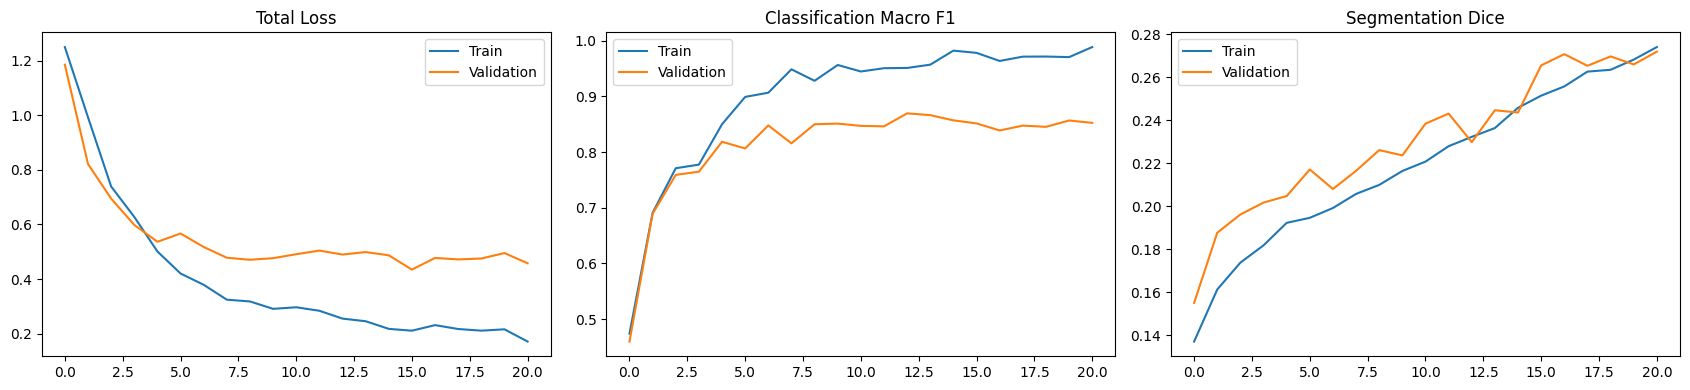

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(history_e2["train_loss"], label="Train")
axes[0].plot(history_e2["val_loss"], label="Validation")
axes[0].set_title("Total Loss")
axes[0].legend()

axes[1].plot(history_e2["train_f1"], label="Train")
axes[1].plot(history_e2["val_f1"], label="Validation")
axes[1].set_title("Classification Macro F1")
axes[1].legend()

axes[2].plot(history_e2["train_dice"], label="Train")
axes[2].plot(history_e2["val_dice"], label="Validation")
axes[2].set_title("Segmentation Dice")
axes[2].legend()

plt.tight_layout()
plt.savefig(
    os.path.join(E2_DIR, "training_curves.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [28]:
checkpoint_e2 = torch.load(
    os.path.join(E2_DIR, "best_model_e2.pth"),
    map_location=DEVICE,
    weights_only=False
)

model_e2.load_state_dict(
    checkpoint_e2["model_state_dict"]
)

test_metrics_e2 = run_epoch_e2(
    model_e2,
    test_loader
)

y_true_e2 = test_metrics_e2["labels"]
y_pred_e2 = test_metrics_e2["predictions"]
y_prob_e2 = test_metrics_e2["probabilities"]

test_accuracy_e2 = accuracy_score(
    y_true_e2, y_pred_e2
)

test_f1_e2 = f1_score(
    y_true_e2,
    y_pred_e2,
    average="macro"
)

test_auc_e2 = roc_auc_score(
    y_true_e2,
    y_prob_e2,
    multi_class="ovr",
    average="macro"
)

print("BEST CHECKPOINT")
print("Epoch:", checkpoint_e2["epoch"])
print("Validation Macro F1:", checkpoint_e2["best_val_f1"])

print("\nTEST RESULTS")
print(f"Accuracy: {test_accuracy_e2:.4f}")
print(f"Macro F1: {test_f1_e2:.4f}")
print(f"Macro AUC: {test_auc_e2:.4f}")
print(f"Mean segmentation Dice: {test_metrics_e2['dice']:.4f}")

print("\nClassification Report")

print(
    classification_report(
        y_true_e2,
        y_pred_e2,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

BEST CHECKPOINT
Epoch: 13
Validation Macro F1: 0.869354668912517

TEST RESULTS
Accuracy: 0.8974
Macro F1: 0.8988
Macro AUC: 0.9686
Mean segmentation Dice: 0.2466

Classification Report
              precision    recall  f1-score   support

      benign     0.9500    0.8636    0.9048        66
   malignant     0.8235    0.9032    0.8615        31
      normal     0.8696    1.0000    0.9302        20

    accuracy                         0.8974       117
   macro avg     0.8810    0.9223    0.8988       117
weighted avg     0.9027    0.8974    0.8977       117



In [29]:
model_e2.eval()

all_dice = []
positive_dice = []
normal_dice = []
false_positive_area = []

with torch.no_grad():

    for images, masks, labels in test_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        _, seg_logits = model_e2(images)

        predictions = (
            torch.sigmoid(seg_logits) > 0.5
        ).float()

        for i in range(len(labels)):

            pred = predictions[i, 0]
            target = masks[i, 0]

            intersection = (pred * target).sum()
            denominator = pred.sum() + target.sum()

            dice = (
                2 * intersection + 1e-6
            ) / (
                denominator + 1e-6
            )

            gt_area = target.sum().item()
            pred_area = pred.sum().item()

            all_dice.append(dice.item())

            if gt_area > 0:
                positive_dice.append(dice.item())
            else:
                normal_dice.append(dice.item())
                false_positive_area.append(
                    pred_area / pred.numel()
                )

print("Segmentation evaluation")
print("-----------------------")
print(f"Overall Dice: {np.mean(all_dice):.4f}")
print(f"Lesion-positive Dice: {np.mean(positive_dice):.4f}")
print(f"Empty-mask Dice: {np.mean(normal_dice):.4f}")
print(
    "Mean predicted foreground area on empty masks:",
    f"{np.mean(false_positive_area):.4%}"
)

Segmentation evaluation
-----------------------
Overall Dice: 0.6547
Lesion-positive Dice: 0.6145
Empty-mask Dice: 0.8500
Mean predicted foreground area on empty masks: 0.3326%


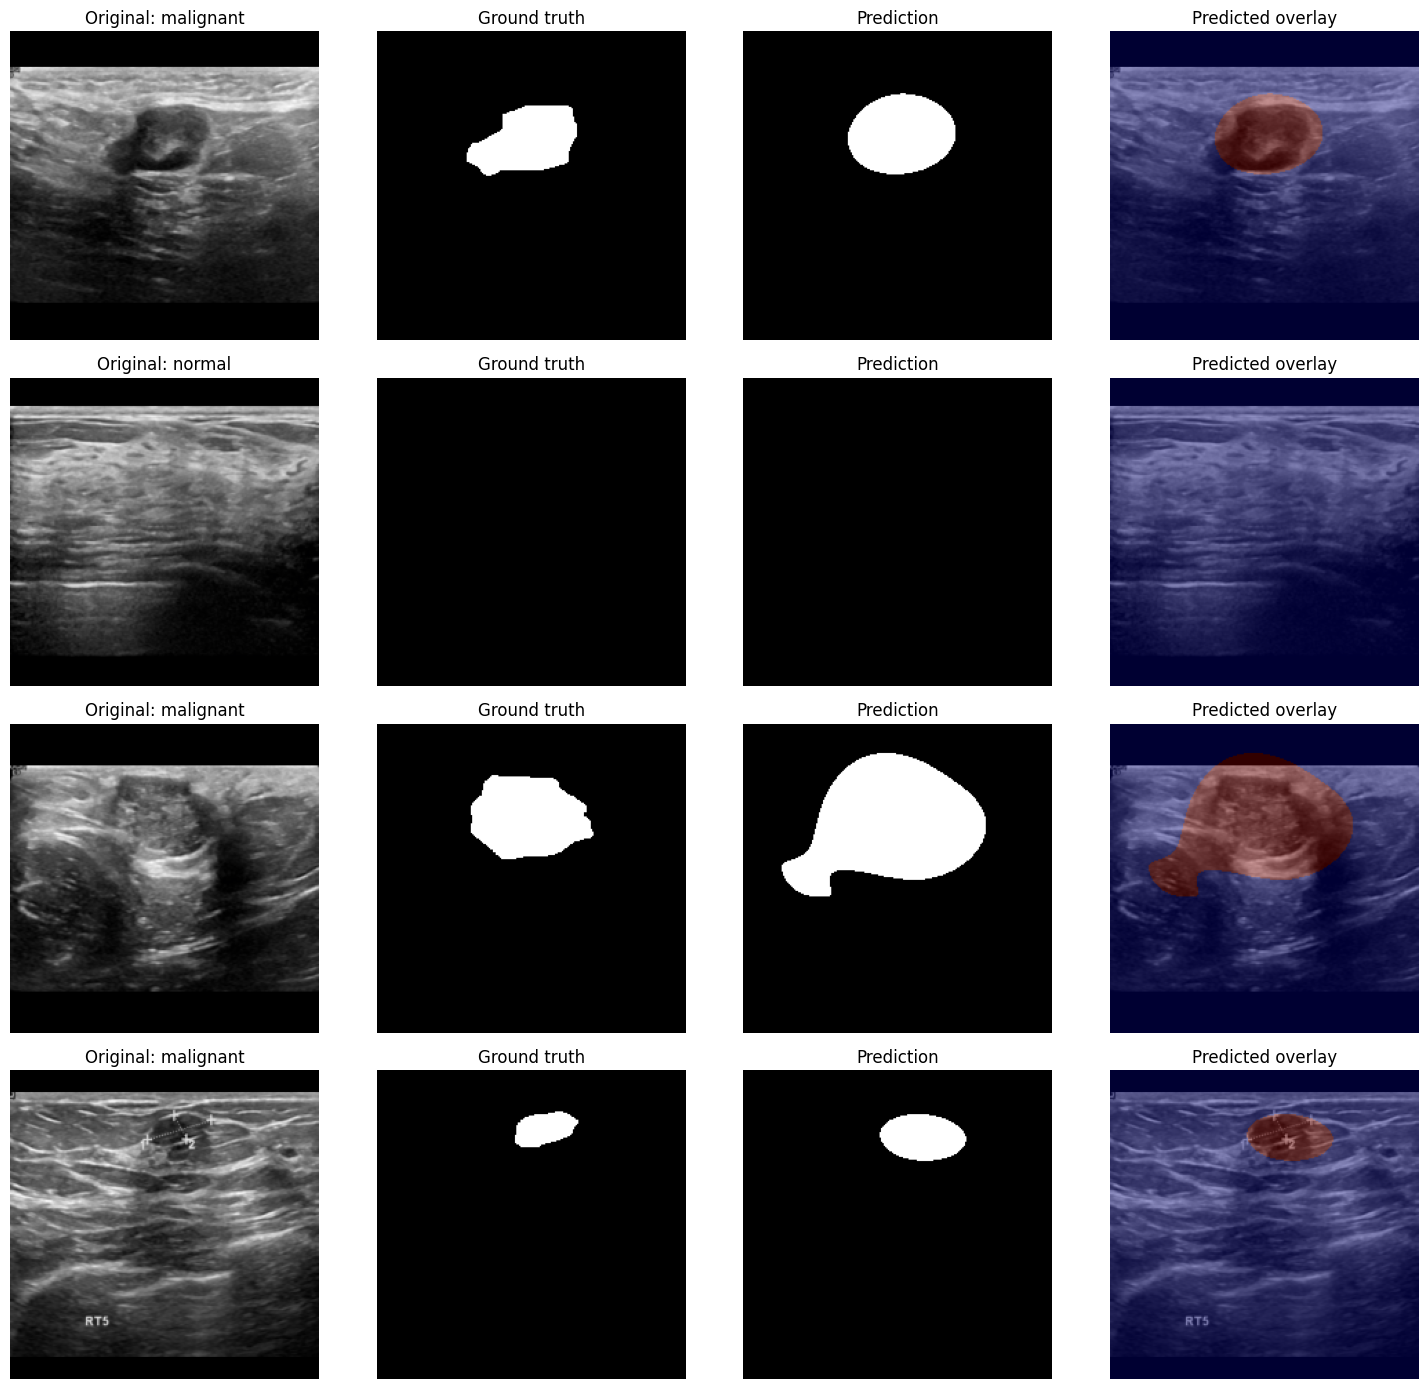

In [30]:
model_e2.eval()

images, masks, labels = next(iter(test_loader))

with torch.no_grad():
    class_logits, seg_logits = model_e2(images.to(DEVICE))

pred_masks = (
    torch.sigmoid(seg_logits) > 0.5
).float().cpu()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(4, 4, figsize=(15, 14))

for i in range(4):

    image = images[i].permute(1, 2, 0).numpy()
    image = np.clip(image * std + mean, 0, 1)

    gt = masks[i, 0].numpy()
    pred = pred_masks[i, 0].numpy()

    label = CLASSES[labels[i].item()]

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Original: {label}")

    axes[i, 1].imshow(gt, cmap="gray")
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(pred, cmap="gray")
    axes[i, 2].set_title("Prediction")

    axes[i, 3].imshow(image)
    axes[i, 3].imshow(pred, cmap="jet", alpha=0.4)
    axes[i, 3].set_title("Predicted overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(E2_DIR, "segmentation_examples.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [31]:
model_e2.eval()

class_dice = {
    "benign": [],
    "malignant": []
}

all_lesion_dice = []
normal_fp_area = []

with torch.no_grad():

    for images, masks, labels in test_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        _, seg_logits = model_e2(images)

        predictions = (
            torch.sigmoid(seg_logits) >= 0.5
        ).float()

        for i in range(len(labels)):

            pred = predictions[i, 0]
            target = masks[i, 0]

            intersection = (pred * target).sum()

            denominator = pred.sum() + target.sum()

            dice = (
                2 * intersection + 1e-6
            ) / (
                denominator + 1e-6
            )

            label = CLASSES[labels[i].item()]

            if label in ["benign", "malignant"]:

                class_dice[label].append(dice.item())
                all_lesion_dice.append(dice.item())

            else:
                normal_fp_area.append(
                    pred.sum().item() / pred.numel()
                )

results = {
    "Benign Dice": np.mean(class_dice["benign"]),
    "Malignant Dice": np.mean(class_dice["malignant"]),
    "Overall lesion Dice": np.mean(all_lesion_dice),
    "Normal false-positive area": np.mean(normal_fp_area)
}

display(pd.DataFrame(
    results.items(),
    columns=["Metric", "Value"]
))

,Metric,Value
0,Benign Dice,0.575817
1,Malignant Dice,0.696748
2,Overall lesion Dice,0.614465
3,Normal false-positive area,0.003326


# Multi-scale Feature Fusion for Breast Lesion Segmentation and Classification

In [32]:
import os
import json
import copy
import random
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import BytesIO
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)

from scipy.ndimage import distance_transform_edt

SEED = 42
IMG_SIZE = 224
NUM_CLASSES = 3
CLASSES = ["benign", "malignant", "normal"]

BATCH_SIZE = 16
EPOCHS = 40
PATIENCE = 8
LR = 1e-4
WEIGHT_DECAY = 1e-4

LAMBDA_SEG = 0.3

PROJECT_DIR = "/content/BUSI_Reliable_AI"

DIRS = [
    "checkpoints/E3",
    "results/E3",
    "results/E4_gradcam",
    "results/E5_uncertainty",
    "results/E6_calibration",
    "results/E7_robustness",
    "results/E8_statistics",
    "figures",
    "metadata"
]

for directory in DIRS:
    os.makedirs(
        os.path.join(PROJECT_DIR, directory),
        exist_ok=True
    )

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Device: cuda
GPU: Tesla T4


In [33]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class MultiScaleBUSI(nn.Module):

    def __init__(self, num_classes=3, pretrained=True):
        super().__init__()

        weights = (
            models.EfficientNet_B0_Weights.DEFAULT
            if pretrained else None
        )

        base = models.efficientnet_b0(weights=weights)
        self.encoder = base.features

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(1280, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

        self.lat8 = nn.Conv2d(1280, 128, 1)
        self.lat4 = nn.Conv2d(80, 128, 1)
        self.lat3 = nn.Conv2d(40, 128, 1)
        self.lat2 = nn.Conv2d(24, 128, 1)

        self.refine4 = ConvBlock(128, 128)
        self.refine3 = ConvBlock(128, 128)
        self.refine2 = ConvBlock(128, 128)

        self.seg_head = nn.Sequential(
            ConvBlock(128, 64),
            nn.Conv2d(64, 1, kernel_size=1)
        )

    def forward(self, x):

        x = self.encoder[0](x)
        x = self.encoder[1](x)

        f2 = self.encoder[2](x)
        f3 = self.encoder[3](f2)
        f4 = self.encoder[4](f3)

        x = self.encoder[5](f4)
        x = self.encoder[6](x)
        x = self.encoder[7](x)
        f8 = self.encoder[8](x)

        pooled = self.pool(f8).flatten(1)
        class_logits = self.classifier(pooled)

        p8 = self.lat8(f8)

        p4 = self.lat4(f4) + F.interpolate(
            p8,
            size=f4.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        p4 = self.refine4(p4)

        p3 = self.lat3(f3) + F.interpolate(
            p4,
            size=f3.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        p3 = self.refine3(p3)

        p2 = self.lat2(f2) + F.interpolate(
            p3,
            size=f2.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        p2 = self.refine2(p2)

        seg_features = F.interpolate(
            p2,
            size=(IMG_SIZE, IMG_SIZE),
            mode="bilinear",
            align_corners=False
        )

        seg_logits = self.seg_head(seg_features)

        return class_logits, seg_logits, f8


model_e3 = MultiScaleBUSI().to(DEVICE)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model_e3.parameters() if p.requires_grad)
)

with torch.no_grad():
    sample = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
    cls_out, seg_out, features = model_e3(sample)

print("Classification:", cls_out.shape)
print("Segmentation:", seg_out.shape)
print("Feature map:", features.shape)

del sample, cls_out, seg_out, features

Trainable parameters: 5036096
Classification: torch.Size([2, 3])
Segmentation: torch.Size([2, 1, 224, 224])
Feature map: torch.Size([2, 1280, 7, 7])


In [34]:
from sklearn.utils.class_weight import compute_class_weight

class MultiTaskLoss(nn.Module):

    def __init__(self, weights, lambda_seg=0.3):
        super().__init__()

        self.cls_loss = nn.CrossEntropyLoss(
            weight=weights
        )

        self.lambda_seg = lambda_seg

    def forward(self, cls_logits, seg_logits, labels, masks):

        classification = self.cls_loss(
            cls_logits,
            labels
        )

        bce = F.binary_cross_entropy_with_logits(
            seg_logits,
            masks
        )

        probs = torch.sigmoid(seg_logits)

        intersection = (probs * masks).sum((1, 2, 3))

        denominator = (
            probs.sum((1, 2, 3))
            + masks.sum((1, 2, 3))
        )

        dice = (
            2 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )

        segmentation = 0.5 * bce + 0.5 * (1 - dice.mean())

        total = classification + self.lambda_seg * segmentation

        return total, classification, segmentation

# Calculate class weights for the training split
raw_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["class_label"].map({
        "benign": 0,
        "malignant": 1,
        "normal": 2
    }).values
)

class_weights = torch.tensor(
    raw_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion_e3 = MultiTaskLoss(
    class_weights,
    LAMBDA_SEG
).to(DEVICE)

optimizer_e3 = torch.optim.AdamW(
    model_e3.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler_e3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_e3,
    mode="max",
    factor=0.5,
    patience=3
)

scaler_e3 = torch.amp.GradScaler(
    "cuda",
    enabled=DEVICE.type == "cuda"
)

In [35]:
import os
import torch

def save_e3_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    epoch,
    best_val_f1,
    config,
    history=None
):
    os.makedirs(os.path.dirname(path), exist_ok=True)

    checkpoint = {
        "model_name": "MultiScaleBUSI",
        "model_state_dict": model.state_dict(),

        "model_config": config,

        "epoch": epoch,
        "best_val_macro_f1": float(best_val_f1),

        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": (
            scheduler.state_dict() if scheduler else None
        ),

        "preprocessing": {
            "image_size": 224,
            "normalization": "ImageNet",
            "mean": [0.485, 0.456, 0.406],
            "std": [0.229, 0.224, 0.225],
            "input_channels": 3
        },

        "class_mapping": {
            "benign": 0,
            "malignant": 1,
            "normal": 2
        },

        "calibration": {
            "method": "temperature_scaling",
            "temperature": 1.2749673128128052
        },

        "random_seed": 42,
        "history": history
    }

    torch.save(checkpoint, path)

    print(f"Checkpoint saved: {path}")
    print(f"Size: {os.path.getsize(path) / (1024 ** 2):.2f} MB")

In [36]:
def calculate_segmentation_metrics(pred, target):

    scores = []

    for p, t in zip(pred, target):

        p = p.reshape(-1).float()
        t = t.reshape(-1).float()

        intersection = (p * t).sum()
        denominator = p.sum() + t.sum()

        dice = (
            2 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )

        scores.append(dice.item())

    return scores


def run_epoch_e3(model, loader, optimizer=None):

    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0
    total_cls_loss = 0
    total_seg_loss = 0

    all_labels = []
    all_preds = []
    all_probs = []

    lesion_dice = []
    normal_fp = []

    for images, masks, labels in loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=DEVICE.type == "cuda"
            ):

                cls_logits, seg_logits, _ = model(images)

                loss, cls_loss, seg_loss = criterion_e3(
                    cls_logits,
                    seg_logits,
                    labels,
                    masks
                )

            if training:
                scaler_e3.scale(loss).backward()
                scaler_e3.step(optimizer)
                scaler_e3.update()

        probs = torch.softmax(cls_logits.float(), dim=1)
        preds = probs.argmax(dim=1)

        pred_masks = (
            torch.sigmoid(seg_logits.float()) >= 0.5
        ).float()

        dice_values = calculate_segmentation_metrics(
            pred_masks,
            masks
        )

        for i, label in enumerate(labels.cpu().numpy()):

            if label in [0, 1]:
                lesion_dice.append(dice_values[i])
            else:
                normal_fp.append(
                    pred_masks[i].mean().item()
                )

        n = labels.size(0)

        total_loss += loss.item() * n
        total_cls_loss += cls_loss.item() * n
        total_seg_loss += seg_loss.item() * n

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.detach().cpu().numpy())

    return {
        "loss": total_loss / len(loader.dataset),
        "cls_loss": total_cls_loss / len(loader.dataset),
        "seg_loss": total_seg_loss / len(loader.dataset),
        "macro_f1": f1_score(
            all_labels,
            all_preds,
            average="macro",
            zero_division=0
        ),
        "accuracy": accuracy_score(all_labels, all_preds),
        "lesion_dice": float(np.mean(lesion_dice)),
        "normal_fp": float(np.mean(normal_fp)),
        "labels": np.array(all_labels),
        "predictions": np.array(all_preds),
        "probabilities": np.array(all_probs)
    }

In [37]:
import random
from io import BytesIO
from PIL import Image, ImageOps
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

# Fallback definition of BUSIDataset with augmentation support to prevent NameErrors/TypeErrors
class AugmentableBUSIDataset(Dataset):
    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.label_map = {
            "benign": 0,
            "malignant": 1,
            "normal": 2
        }
        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
        self.color_jitter = transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10
        )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(BytesIO(row["image"]["bytes"])).convert("RGB")
        mask = Image.open(BytesIO(row["mask"]["bytes"])).convert("L")

        image = ImageOps.pad(image, (IMG_SIZE, IMG_SIZE), method=Image.Resampling.BILINEAR)
        mask = ImageOps.pad(mask, (IMG_SIZE, IMG_SIZE), method=Image.Resampling.NEAREST)

        if self.augment:
            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)
            if random.random() < 0.5:
                angle = random.uniform(-10, 10)
                image = TF.rotate(image, angle, interpolation=InterpolationMode.BILINEAR, fill=0)
                mask = TF.rotate(mask, angle, interpolation=InterpolationMode.NEAREST, fill=0)
            image = self.color_jitter(image)

        image = TF.to_tensor(image)
        image = self.normalize(image)
        mask = torch.from_numpy((np.array(mask) > 0).astype(np.float32)).unsqueeze(0)
        label = self.label_map[row["class_label"]]
        return image, mask, torch.tensor(label, dtype=torch.long)

# Instantiate datasets using the updated dataset class
train_dataset = AugmentableBUSIDataset(train_df, augment=True)
val_dataset = AugmentableBUSIDataset(val_df, augment=False)
test_dataset = AugmentableBUSIDataset(test_df, augment=False)

PIN_MEMORY = DEVICE.type == "cuda"

# Re-create the data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=PIN_MEMORY
)

history_e3 = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
    "train_dice": [],
    "val_dice": []
}

best_f1_e3 = -1
best_epoch_e3 = 0
wait = 0

E3_PATH = os.path.join(
    PROJECT_DIR,
    "checkpoints/E3/best_model_e3.pth"
)

for epoch in range(EPOCHS):
    train_m = run_epoch_e3(
        model_e3,
        train_loader,
        optimizer_e3
    )
    val_m = run_epoch_e3(
        model_e3,
        val_loader
    )
    scheduler_e3.step(val_m["macro_f1"])

    history_e3["train_loss"].append(train_m["loss"])
    history_e3["val_loss"].append(val_m["loss"])
    history_e3["train_f1"].append(train_m["macro_f1"])
    history_e3["val_f1"].append(val_m["macro_f1"])
    history_e3["train_dice"].append(train_m["lesion_dice"])
    history_e3["val_dice"].append(val_m["lesion_dice"])

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss {train_m['loss']:.4f} | "
        f"Val Loss {val_m['loss']:.4f} | "
        f"Val F1 {val_m['macro_f1']:.4f} | "
        f"Val Dice {val_m['lesion_dice']:.4f}"
    )

    if val_m["macro_f1"] > best_f1_e3:
        best_f1_e3 = val_m["macro_f1"]
        best_epoch_e3 = epoch + 1
        wait = 0

        checkpoint = {
            "epoch": best_epoch_e3,
            "model_state_dict": copy.deepcopy(model_e3.state_dict()),
            "optimizer_state_dict": copy.deepcopy(optimizer_e3.state_dict()),
            "scheduler_state_dict": copy.deepcopy(scheduler_e3.state_dict()),
            "scaler_state_dict": copy.deepcopy(scaler_e3.state_dict()),
            "best_val_f1": best_f1_e3,
            "val_metrics": {
                "macro_f1": val_m["macro_f1"],
                "accuracy": val_m["accuracy"],
                "lesion_dice": val_m["lesion_dice"]
            },
            "config": {
                "architecture": "MultiScaleBUSI",
                "backbone": "EfficientNet-B0",
                "pretrained": True,
                "image_size": IMG_SIZE,
                "classes": CLASSES,
                "class_weights": class_weights.cpu().tolist(),
                "lambda_seg": LAMBDA_SEG,
                "learning_rate": LR,
                "weight_decay": WEIGHT_DECAY,
                "batch_size": BATCH_SIZE,
                "seed": SEED,
                "normalization_mean": [0.485, 0.456, 0.406],
                "normalization_std": [0.229, 0.224, 0.225]
            },
            "train_ids": train_df["image_id"].tolist(),
            "val_ids": val_df["image_id"].tolist(),
            "test_ids": test_df["image_id"].tolist(),
            "history": copy.deepcopy(history_e3)
        }

        torch.save(checkpoint, E3_PATH)
        print("Best checkpoint saved.")
    else:
        wait += 1

    if wait >= PATIENCE:
        print("Early stopping.")
        break

print("Best epoch:", best_epoch_e3)
print("Best validation F1:", best_f1_e3)

Epoch 01 | Train Loss 1.2828 | Val Loss 1.2204 | Val F1 0.4164 | Val Dice 0.4092
Best checkpoint saved.
Epoch 02 | Train Loss 1.1265 | Val Loss 0.9378 | Val F1 0.7176 | Val Dice 0.4433
Best checkpoint saved.
Epoch 03 | Train Loss 0.8609 | Val Loss 0.6867 | Val F1 0.7712 | Val Dice 0.5953
Best checkpoint saved.
Epoch 04 | Train Loss 0.6576 | Val Loss 0.6087 | Val F1 0.7842 | Val Dice 0.5892
Best checkpoint saved.
Epoch 05 | Train Loss 0.5317 | Val Loss 0.5460 | Val F1 0.8302 | Val Dice 0.6638
Best checkpoint saved.
Epoch 06 | Train Loss 0.4466 | Val Loss 0.5219 | Val F1 0.8350 | Val Dice 0.6442
Best checkpoint saved.
Epoch 07 | Train Loss 0.3571 | Val Loss 0.5379 | Val F1 0.8297 | Val Dice 0.6348
Epoch 08 | Train Loss 0.3255 | Val Loss 0.5247 | Val F1 0.8578 | Val Dice 0.6775
Best checkpoint saved.
Epoch 09 | Train Loss 0.3405 | Val Loss 0.5552 | Val F1 0.8367 | Val Dice 0.6574
Epoch 10 | Train Loss 0.2919 | Val Loss 0.5545 | Val F1 0.7943 | Val Dice 0.6891
Epoch 11 | Train Loss 0.2550 

In [38]:
checkpoint_e3 = torch.load(
    E3_PATH,
    map_location=DEVICE,
    weights_only=False
)

model_e3.load_state_dict(
    checkpoint_e3["model_state_dict"]
)

test_e3 = run_epoch_e3(model_e3, test_loader)

y_true_e3 = test_e3["labels"]
y_pred_e3 = test_e3["predictions"]
y_prob_e3 = test_e3["probabilities"]

test_auc_e3 = roc_auc_score(
    y_true_e3,
    y_prob_e3,
    multi_class="ovr",
    average="macro"
)

print("E3 TEST RESULTS")
print("Accuracy:", accuracy_score(y_true_e3, y_pred_e3))
print("Macro F1:", f1_score(y_true_e3, y_pred_e3, average="macro"))
print("Macro AUC:", test_auc_e3)
print("Lesion Dice:", test_e3["lesion_dice"])

print(classification_report(
    y_true_e3,
    y_pred_e3,
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

E3 TEST RESULTS
Accuracy: 0.8974358974358975
Macro F1: 0.8961263979256783
Macro AUC: 0.9570238227424128
Lesion Dice: 0.6774147611306255
              precision    recall  f1-score   support

      benign     0.9091    0.9091    0.9091        66
   malignant     0.8667    0.8387    0.8525        31
      normal     0.9048    0.9500    0.9268        20

    accuracy                         0.8974       117
   macro avg     0.8935    0.8993    0.8961       117
weighted avg     0.8971    0.8974    0.8971       117



In [39]:
def hd95_score(pred, target):

    pred = np.asarray(pred, dtype=bool)
    target = np.asarray(target, dtype=bool)

    if not pred.any() or not target.any():
        return np.nan

    distance_target = distance_transform_edt(~target)
    distance_pred = distance_transform_edt(~pred)

    distances = np.concatenate([
        distance_target[pred],
        distance_pred[target]
    ])

    return float(np.percentile(distances, 95))


model_e3.eval()

hd95_values = []
dice_by_class = {"benign": [], "malignant": []}

with torch.no_grad():

    for images, masks, labels in test_loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        _, seg_logits, _ = model_e3(images)

        pred_masks = (
            torch.sigmoid(seg_logits) >= 0.5
        ).cpu().numpy()

        gt_masks = masks.cpu().numpy()

        for i, label in enumerate(labels.numpy()):

            if label not in [0, 1]:
                continue

            pred = pred_masks[i, 0]
            target = gt_masks[i, 0]

            hd = hd95_score(pred, target)

            if np.isfinite(hd):
                hd95_values.append(hd)

            intersection = (pred & target.astype(bool)).sum()
            denominator = pred.sum() + target.sum()

            dice = (
                2 * intersection + 1e-6
            ) / (
                denominator + 1e-6
            )

            dice_by_class[CLASSES[label]].append(dice)

print("Lesion-positive HD95:", np.mean(hd95_values))
print("Benign Dice:", np.mean(dice_by_class["benign"]))
print("Malignant Dice:", np.mean(dice_by_class["malignant"]))

Lesion-positive HD95: 22.589101654749083
Benign Dice: 0.6614906575353978
Malignant Dice: 0.7109124815905853


## Explainability with Grad-CAM

In [40]:
def generate_gradcam(model, image, target_class=None):

    model.eval()

    image = image.unsqueeze(0).to(DEVICE)
    activations = {}

    def capture_features(module, inputs, output):
        activations["features"] = output

    handle = model.encoder[8].register_forward_hook(
        capture_features
    )

    with torch.enable_grad():

        model.zero_grad(set_to_none=True)

        cls_logits, _, _ = model(image)

        if target_class is None:
            target_class = cls_logits.argmax(dim=1).item()

        score = cls_logits[0, target_class]

        features = activations["features"]

        gradients = torch.autograd.grad(
            score,
            features
        )[0]

        weights = gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * features
        ).sum(dim=1, keepdim=True)

        cam = F.relu(cam)

        cam = F.interpolate(
            cam,
            size=(IMG_SIZE, IMG_SIZE),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0]

        cam = (
            cam - cam.min()
        ) / (
            cam.max() - cam.min() + 1e-8
        )

    handle.remove()

    return cam.detach().cpu().numpy(), target_class

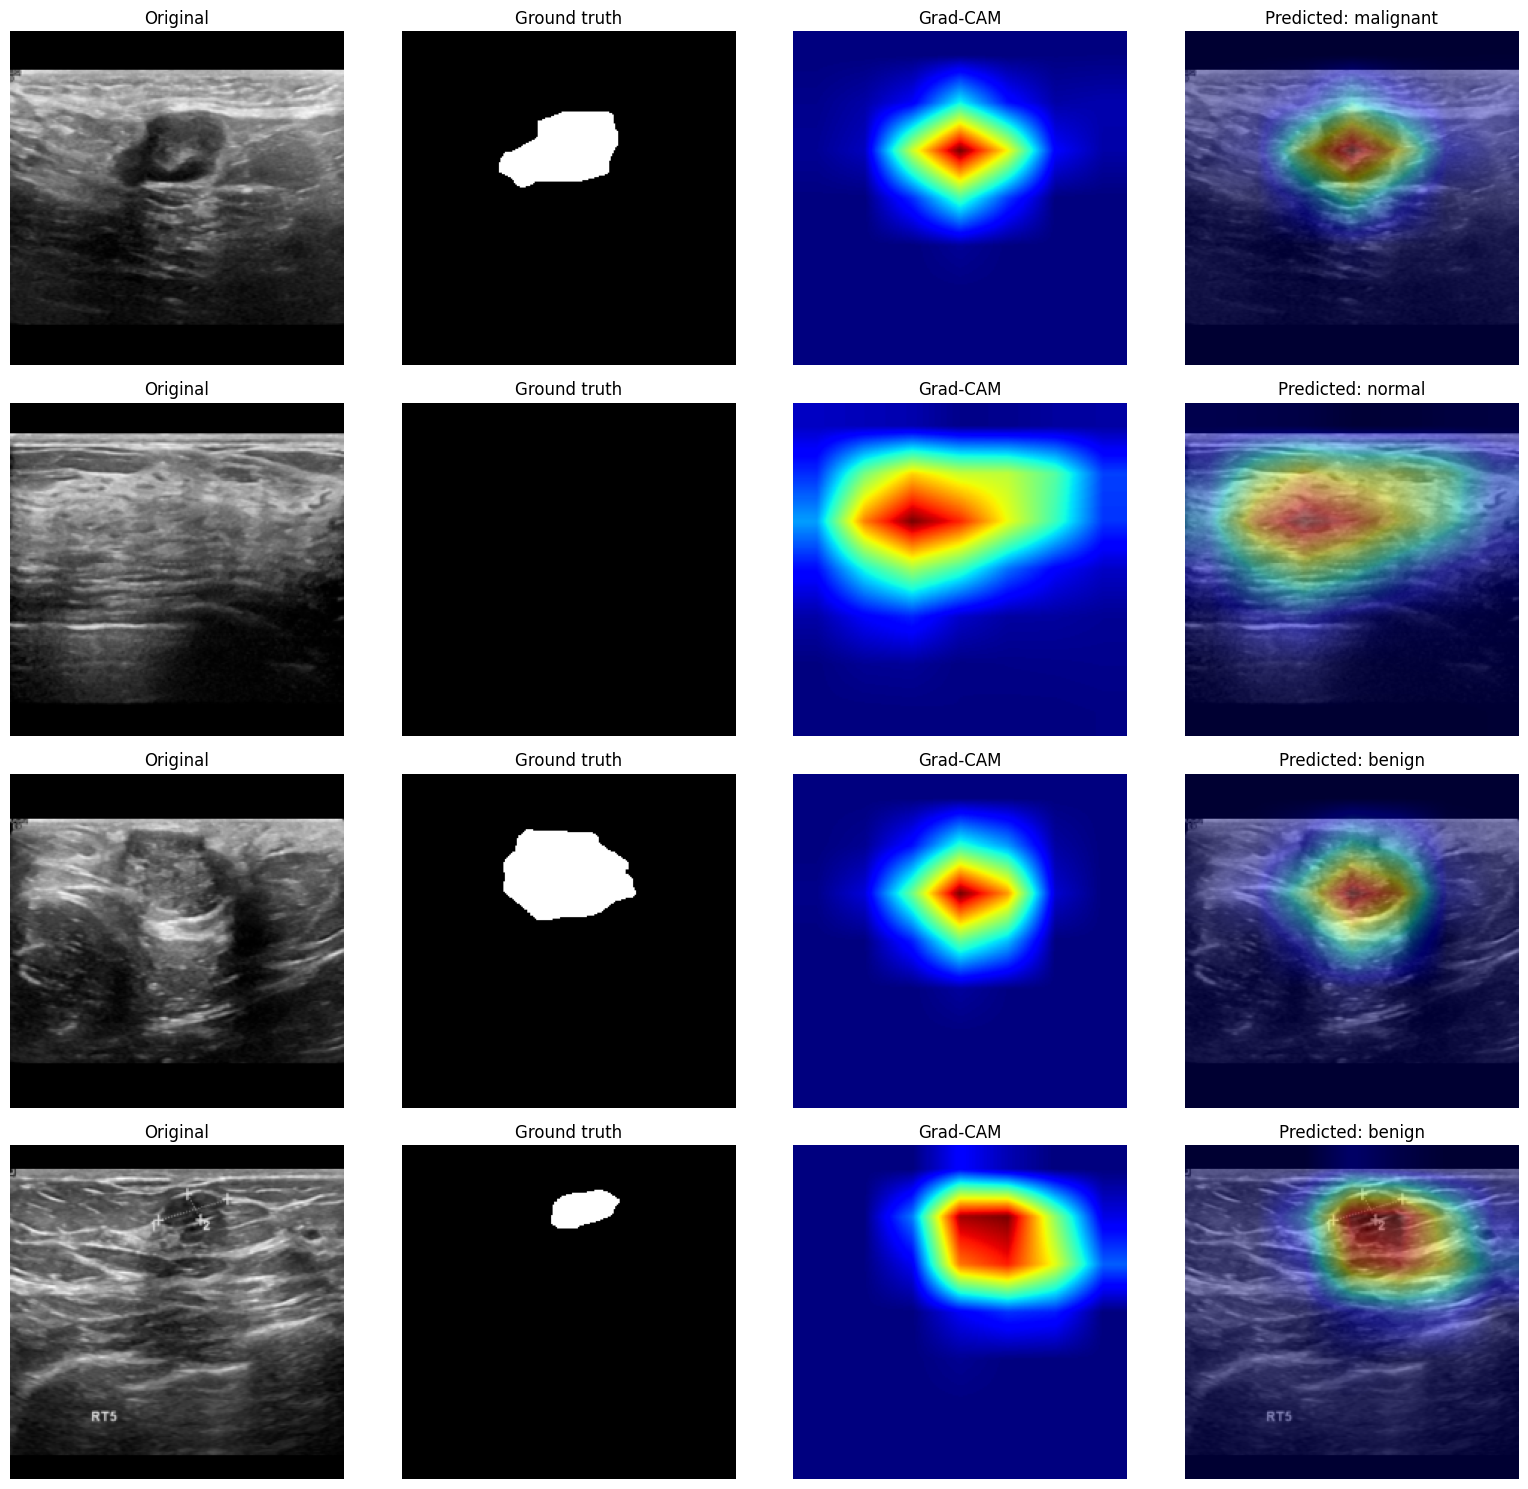

In [41]:
def denormalize_image(image):

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    image = image.cpu() * std + mean

    return image.clamp(0, 1).permute(1, 2, 0).numpy()


model_e3.eval()

images, masks, labels = next(iter(test_loader))

fig, axes = plt.subplots(4, 4, figsize=(16, 15))

gradcam_metrics = []

for i in range(4):

    cam, predicted_class = generate_gradcam(
        model_e3,
        images[i]
    )

    image = denormalize_image(images[i])
    mask = masks[i, 0].numpy()

    cam_binary = cam >= 0.5

    union = np.logical_or(cam_binary, mask > 0).sum()
    intersection = np.logical_and(
        cam_binary, mask > 0
    ).sum()

    overlap = intersection / (union + 1e-8)

    pointing = (
        int(mask[np.unravel_index(np.argmax(cam), cam.shape)] > 0)
        if mask.sum() > 0 else np.nan
    )

    gradcam_metrics.append({
        "true_class": CLASSES[labels[i].item()],
        "predicted_class": CLASSES[predicted_class],
        "gradcam_mask_iou": overlap,
        "pointing_game": pointing
    })

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(cam, cmap="jet")
    axes[i, 2].set_title("Grad-CAM")

    axes[i, 3].imshow(image)
    axes[i, 3].imshow(cam, cmap="jet", alpha=0.4)
    axes[i, 3].set_title(
        f"Predicted: {CLASSES[predicted_class]}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_DIR, "results/E4_gradcam/examples.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

pd.DataFrame(gradcam_metrics).to_csv(
    os.path.join(PROJECT_DIR, "results/E4_gradcam/metrics.csv"),
    index=False
)

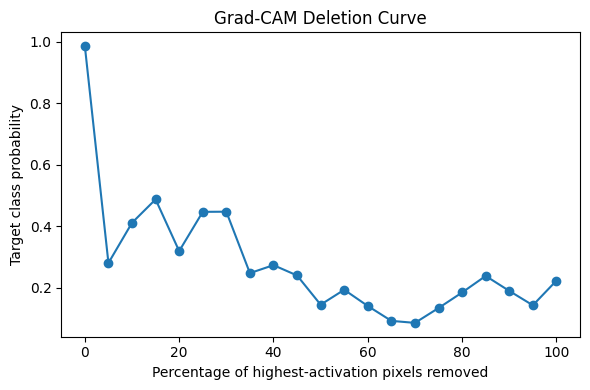

In [42]:
def deletion_curve(model, image, target_class, cam, steps=20):

    model.eval()

    x = image.clone().to(DEVICE)
    baseline = x.mean(dim=(1, 2), keepdim=True)

    cam_tensor = torch.as_tensor(
        cam,
        device=DEVICE,
        dtype=torch.float32
    )

    order = torch.argsort(
        cam_tensor.flatten(),
        descending=True
    )

    confidence = []
    total_pixels = order.numel()

    with torch.no_grad():

        for step in range(steps + 1):

            logits, _, _ = model(x.unsqueeze(0))

            probability = torch.softmax(
                logits, dim=1
            )[0, target_class].item()

            confidence.append(probability)

            if step == steps:
                break

            count = int(
                (step + 1) * total_pixels / steps
            )

            indices = order[:count]

            y = indices // IMG_SIZE
            x_coord = indices % IMG_SIZE

            x[:, y, x_coord] = baseline.expand(
                -1, IMG_SIZE, IMG_SIZE
            )[:, y, x_coord]

    return confidence


# Example for one test image
cam, target = generate_gradcam(model_e3, images[0])

deletion = deletion_curve(
    model_e3,
    images[0],
    target,
    cam
)

plt.figure(figsize=(6, 4))
plt.plot(
    np.linspace(0, 100, len(deletion)),
    deletion,
    marker="o"
)
plt.xlabel("Percentage of highest-activation pixels removed")
plt.ylabel("Target class probability")
plt.title("Grad-CAM Deletion Curve")
plt.tight_layout()
plt.savefig(
    os.path.join(PROJECT_DIR, "results/E4_gradcam/deletion_curve.png"),
    dpi=300
)
plt.show()

## Uncertainty quantification

In [43]:
def mc_dropout_predictions(model, loader, passes=30):

    model.eval()

    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.train()

    all_mean_probs = []
    all_variance = []
    all_entropy = []
    all_labels = []

    with torch.no_grad():

        for images, _, labels in loader:

            images = images.to(DEVICE)

            pass_probs = []

            for _ in range(passes):

                logits, _, _ = model(images)

                probs = torch.softmax(
                    logits.float(), dim=1
                )

                pass_probs.append(probs)

            pass_probs = torch.stack(pass_probs)

            mean_probs = pass_probs.mean(dim=0)
            variance = pass_probs.var(dim=0)

            entropy = -(
                mean_probs *
                torch.log(mean_probs + 1e-8)
            ).sum(dim=1)

            all_mean_probs.append(
                mean_probs.cpu().numpy()
            )

            all_variance.append(
                variance.mean(dim=1).cpu().numpy()
            )

            all_entropy.append(
                entropy.cpu().numpy()
            )

            all_labels.append(labels.numpy())

    model.eval()

    return {
        "probabilities": np.concatenate(all_mean_probs),
        "variance": np.concatenate(all_variance),
        "entropy": np.concatenate(all_entropy),
        "labels": np.concatenate(all_labels)
    }


uncertainty_val = mc_dropout_predictions(
    model_e3,
    val_loader,
    passes=30
)

uncertainty_test = mc_dropout_predictions(
    model_e3,
    test_loader,
    passes=30
)

print(
    "Mean predictive entropy:",
    uncertainty_test["entropy"].mean()
)

print(
    "Mean predictive variance:",
    uncertainty_test["variance"].mean()
)

Mean predictive entropy: 0.29589036
Mean predictive variance: 0.0010986918


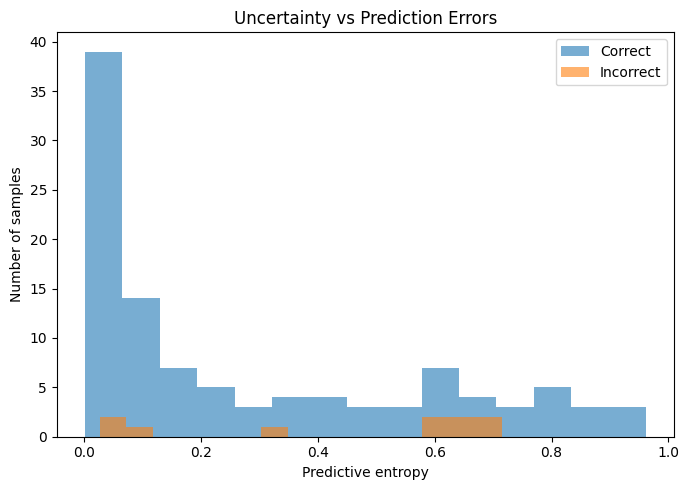

In [44]:
uncertainty_errors = (
    uncertainty_test["probabilities"].argmax(axis=1)
    != uncertainty_test["labels"]
)

plt.figure(figsize=(7, 5))

plt.hist(
    uncertainty_test["entropy"][~uncertainty_errors],
    bins=15,
    alpha=0.6,
    label="Correct"
)

plt.hist(
    uncertainty_test["entropy"][uncertainty_errors],
    bins=15,
    alpha=0.6,
    label="Incorrect"
)

plt.xlabel("Predictive entropy")
plt.ylabel("Number of samples")
plt.title("Uncertainty vs Prediction Errors")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_DIR, "results/E5_uncertainty/entropy_errors.png"),
    dpi=300
)

plt.show()

uncertainty_df = pd.DataFrame({
    "true_label": [
        CLASSES[i] for i in uncertainty_test["labels"]
    ],
    "predicted_label": [
        CLASSES[i]
        for i in uncertainty_test["probabilities"].argmax(axis=1)
    ],
    "entropy": uncertainty_test["entropy"],
    "predictive_variance": uncertainty_test["variance"],
    "correct": ~uncertainty_errors
})

uncertainty_df.to_csv(
    os.path.join(PROJECT_DIR, "results/E5_uncertainty/predictions.csv"),
    index=False
)

## Confidence calibration

In [45]:
def expected_calibration_error(y_true, probabilities, bins=10):

    confidences = probabilities.max(axis=1)
    predictions = probabilities.argmax(axis=1)

    correctness = (predictions == y_true).astype(float)

    edges = np.linspace(0, 1, bins + 1)
    ece = 0.0

    for i in range(bins):

        lower = edges[i]
        upper = edges[i + 1]

        if i == bins - 1:
            selected = (
                (confidences >= lower) &
                (confidences <= upper)
            )
        else:
            selected = (
                (confidences >= lower) &
                (confidences < upper)
            )

        if selected.sum() == 0:
            continue

        accuracy = correctness[selected].mean()
        confidence = confidences[selected].mean()

        ece += (
            selected.mean() *
            abs(accuracy - confidence)
        )

    return float(ece)


def multiclass_brier(y_true, probabilities):

    targets = np.eye(NUM_CLASSES)[y_true]

    return float(
        np.mean(
            np.sum((probabilities - targets) ** 2, axis=1)
        )
    )

In [46]:
def collect_logits(model, loader):

    model.eval()

    logits_all = []
    labels_all = []

    with torch.no_grad():

        for images, _, labels in loader:

            images = images.to(DEVICE)

            logits, _, _ = model(images)

            logits_all.append(logits.cpu())
            labels_all.append(labels)

    return (
        torch.cat(logits_all),
        torch.cat(labels_all)
    )


val_logits, val_labels = collect_logits(
    model_e3, val_loader
)

test_logits, test_labels = collect_logits(
    model_e3, test_loader
)

In [47]:
temperature = torch.nn.Parameter(
    torch.ones(1, device=DEVICE)
)

optimizer_temp = torch.optim.LBFGS(
    [temperature],
    lr=0.01,
    max_iter=100
)

val_logits_device = val_logits.to(DEVICE)
val_labels_device = val_labels.to(DEVICE)

def temperature_closure():

    optimizer_temp.zero_grad()

    loss = F.cross_entropy(
        val_logits_device / temperature.clamp(min=0.05),
        val_labels_device
    )

    loss.backward()

    return loss


optimizer_temp.step(temperature_closure)

optimal_temperature = temperature.detach().clamp(
    min=0.05
).item()

print("Optimal temperature:", optimal_temperature)

Optimal temperature: 1.183189034461975


In [48]:
test_probs_raw = torch.softmax(
    test_logits,
    dim=1
).numpy()

test_probs_calibrated = torch.softmax(
    test_logits / optimal_temperature,
    dim=1
).numpy()

y_test = test_labels.numpy()

calibration_results = pd.DataFrame([
    {
        "Method": "Uncalibrated",
        "ECE": expected_calibration_error(
            y_test, test_probs_raw
        ),
        "Brier": multiclass_brier(
            y_test, test_probs_raw
        )
    },
    {
        "Method": "Temperature scaled",
        "ECE": expected_calibration_error(
            y_test, test_probs_calibrated
        ),
        "Brier": multiclass_brier(
            y_test, test_probs_calibrated
        )
    }
])

display(calibration_results)

calibration_results.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results/E6_calibration/metrics.csv"
    ),
    index=False
)

,Method,ECE,Brier
0,Uncalibrated,0.055647,0.167301
1,Temperature scaled,0.058511,0.171947


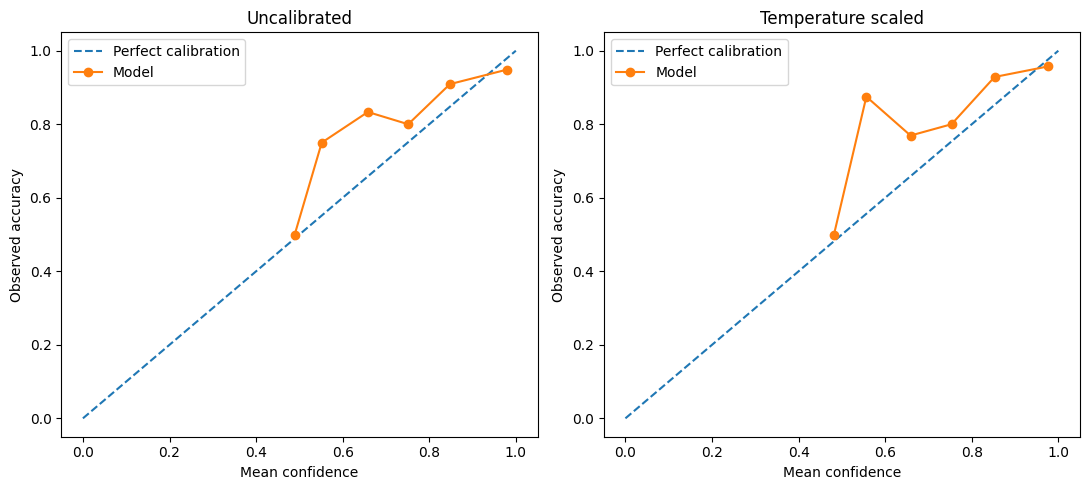

In [49]:
def reliability_data(y_true, probabilities, bins=10):

    confidence = probabilities.max(axis=1)
    prediction = probabilities.argmax(axis=1)
    correct = (prediction == y_true).astype(float)

    edges = np.linspace(0, 1, bins + 1)

    bin_conf = []
    bin_acc = []

    for i in range(bins):

        selected = (
            (confidence >= edges[i]) &
            (confidence < edges[i + 1])
        )

        if selected.sum() == 0:
            continue

        bin_conf.append(confidence[selected].mean())
        bin_acc.append(correct[selected].mean())

    return bin_conf, bin_acc


fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, probs, title in [
    (axes[0], test_probs_raw, "Uncalibrated"),
    (axes[1], test_probs_calibrated, "Temperature scaled")
]:

    conf, acc = reliability_data(y_test, probs)

    ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
    ax.plot(conf, acc, marker="o", label="Model")

    ax.set_xlabel("Mean confidence")
    ax.set_ylabel("Observed accuracy")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/E6_calibration/reliability_diagram.png"
    ),
    dpi=300
)

plt.show()

In [50]:
MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    device=DEVICE
).view(1, 3, 1, 1)

STD = torch.tensor(
    [0.229, 0.224, 0.225],
    device=DEVICE
).view(1, 3, 1, 1)


def denormalize_batch(x):

    return (x * STD + MEAN).clamp(0, 1)


def normalize_batch(x):

    return (x - MEAN) / STD


def perturb_images(images, mode):

    raw = denormalize_batch(images)

    if mode == "noise":
        raw = (
            raw + torch.randn_like(raw) * 0.05
        ).clamp(0, 1)

    elif mode == "brightness":
        raw = (raw * 1.25).clamp(0, 1)

    elif mode == "contrast":
        mean = raw.mean(
            dim=(2, 3),
            keepdim=True
        )
        raw = (
            (raw - mean) * 0.65 + mean
        ).clamp(0, 1)

    elif mode == "blur":
        raw = F.avg_pool2d(
            raw,
            kernel_size=5,
            stride=1,
            padding=2
        )

    return normalize_batch(raw)

In [51]:
def evaluate_robustness(model, loader, perturbation=None):

    model.eval()

    labels_all = []
    predictions_all = []
    probabilities_all = []

    with torch.no_grad():

        for images, _, labels in loader:

            images = images.to(DEVICE)

            if perturbation is not None:
                images = perturb_images(
                    images,
                    perturbation
                )

            logits, _, _ = model(images)

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )

            predictions = probabilities.argmax(dim=1)

            labels_all.extend(labels.numpy())
            predictions_all.extend(
                predictions.cpu().numpy()
            )
            probabilities_all.extend(
                probabilities.cpu().numpy()
            )

    labels_all = np.array(labels_all)
    predictions_all = np.array(predictions_all)
    probabilities_all = np.array(probabilities_all)

    return {
        "accuracy": accuracy_score(
            labels_all, predictions_all
        ),
        "macro_f1": f1_score(
            labels_all,
            predictions_all,
            average="macro"
        ),
        "macro_auc": roc_auc_score(
            labels_all,
            probabilities_all,
            multi_class="ovr",
            average="macro"
        ),
        "predictions": predictions_all,
        "probabilities": probabilities_all,
        "labels": labels_all
    }


robustness_results = []

for mode in [
    None,
    "noise",
    "brightness",
    "contrast",
    "blur"
]:

    result = evaluate_robustness(
        model_e3,
        test_loader,
        perturbation=mode
    )

    robustness_results.append({
        "condition": "Original" if mode is None else mode,
        "accuracy": result["accuracy"],
        "macro_f1": result["macro_f1"],
        "macro_auc": result["macro_auc"]
    })

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df)

robustness_df.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results/E7_robustness/robustness_results.csv"
    ),
    index=False
)

,condition,accuracy,macro_f1,macro_auc
0,Original,0.905983,0.903596,0.956972
1,noise,0.555556,0.299832,0.500193
2,brightness,0.888889,0.879347,0.953976
3,contrast,0.846154,0.844470,0.943258
4,blur,0.666667,0.616412,0.860961


In [52]:
error_indices = np.where(
    y_true_e3 != y_pred_e3
)[0]

error_df = pd.DataFrame({
    "index": error_indices,
    "true_class": [
        CLASSES[y_true_e3[i]] for i in error_indices
    ],
    "predicted_class": [
        CLASSES[y_pred_e3[i]] for i in error_indices
    ],
    "confidence": [
        y_prob_e3[i].max() for i in error_indices
    ],
    "entropy": [
        -np.sum(
            y_prob_e3[i] *
            np.log(y_prob_e3[i] + 1e-8)
        )
        for i in error_indices
    ]
})

display(error_df)

error_df.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results/E7_robustness/error_analysis.csv"
    ),
    index=False
)

,index,true_class,predicted_class,confidence,entropy
0,2,malignant,benign,0.517602,0.709525
1,3,malignant,benign,0.996521,0.025570
2,35,benign,malignant,0.688444,0.624964
3,36,malignant,benign,0.981014,0.106410
4,46,malignant,benign,0.494939,0.773234
5,50,malignant,benign,0.680612,0.660727
6,60,benign,normal,0.997690,0.017565
7,64,normal,benign,0.816321,0.551069
8,88,benign,malignant,0.797381,0.571225
9,112,benign,malignant,0.485699,0.813620


In [53]:
np.savez_compressed(
    os.path.join(
        PROJECT_DIR,
        "results/E3/test_predictions.npz"
    ),
    y_true=y_true_e3,
    y_pred=y_pred_e3,
    y_prob=y_prob_e3,
    probabilities_calibrated=test_probs_calibrated,
    temperature=optimal_temperature
)

print("E3 predictions saved.")

E3 predictions saved.


In [54]:
# Save classification predictions
np.savez_compressed(
    os.path.join(PROJECT_DIR, "results/E3/test_predictions.npz"),
    y_true=y_true_e3,
    y_pred=y_pred_e3,
    y_prob=y_prob_e3,
    temperature=optimal_temperature,
    calibrated_probabilities=test_probs_calibrated
)

# Save test segmentation predictions
model_e3.eval()

segmentation_predictions = []
segmentation_targets = []

with torch.no_grad():

    for images, masks, labels in test_loader:

        images = images.to(DEVICE)

        _, seg_logits, _ = model_e3(images)

        predictions = (
            torch.sigmoid(seg_logits) >= 0.5
        ).cpu().numpy().astype(np.uint8)

        segmentation_predictions.append(predictions)
        segmentation_targets.append(
            masks.numpy().astype(np.uint8)
        )

np.savez_compressed(
    os.path.join(PROJECT_DIR, "results/E3/segmentation_predictions.npz"),
    predictions=np.concatenate(segmentation_predictions),
    targets=np.concatenate(segmentation_targets)
)

# Save final E3 results
final_e3_results = {
    "model": "MultiScaleBUSI",
    "best_epoch": checkpoint_e3["epoch"],
    "validation_macro_f1": checkpoint_e3["best_val_f1"],
    "test_accuracy": float(test_e3["accuracy"]),
    "test_macro_f1": float(test_e3["macro_f1"]),
    "test_macro_auc": float(test_auc_e3),
    "test_lesion_dice": float(test_e3["lesion_dice"]),
    "test_normal_false_positive_area": float(test_e3["normal_fp"]),
    "test_hd95_pixels": float(np.mean(hd95_values)),
    "temperature": float(optimal_temperature)
}

with open(
    os.path.join(PROJECT_DIR, "results/E3/metrics.json"),
    "w"
) as f:
    json.dump(final_e3_results, f, indent=4)

print("E3 results and predictions saved.")

E3 results and predictions saved.


In [55]:
checkpoint_e3["test_metrics"] = final_e3_results

checkpoint_e3["reproducibility"] = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "device": str(DEVICE),
    "random_seed": SEED,
    "test_split_strategy": "Stratified image-level split",
    "patient_level_validation": False,
    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },
    "preprocessing": {
        "size": IMG_SIZE,
        "aspect_ratio_preserved": True,
        "augmentation_training_only": True
    },
    "data_split_ids": {
        "train": train_df["image_id"].tolist(),
        "validation": val_df["image_id"].tolist(),
        "test": test_df["image_id"].tolist()
    },
    "rng_states": {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all()
            if torch.cuda.is_available() else None
    }
}

torch.save(checkpoint_e3, E3_PATH)

print("Complete E3 checkpoint updated.")

Complete E3 checkpoint updated.


In [56]:
metadata = {
    "project": "Reliable and Explainable Breast Ultrasound Analysis",
    "dataset": "SamIndia/BUSI",
    "original_samples": 780,
    "clean_samples": 778,
    "classes": CLASSES,
    "split": {
        "train": len(train_df),
        "validation": len(val_df),
        "test": len(test_df)
    },
    "experiments": [
        "E1 - EfficientNet-B0 baseline",
        "E2 - Multi-task classification and segmentation",
        "E3 - Multi-scale feature fusion",
        "E4 - Grad-CAM explainability",
        "E5 - Uncertainty quantification",
        "E6 - Confidence calibration",
        "E7 - Robustness and error analysis",
        "E8 - Statistical evaluation"
    ],
    "random_seed": SEED,
    "limitations": [
        "Small dataset",
        "Image-level split",
        "No external validation cohort",
        "No patient identifiers"
    ]
}

with open(
    os.path.join(PROJECT_DIR, "metadata/project_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved.")

Metadata saved.


In [57]:
import shutil

ZIP_PATH = shutil.make_archive(
    "/content/BUSI_Reliable_AI",
    "zip",
    PROJECT_DIR
)

print("Project ZIP created:", ZIP_PATH)
print(
    "ZIP size:",
    round(os.path.getsize(ZIP_PATH) / (1024**2), 2),
    "MB"
)

Project ZIP created: /content/BUSI_Reliable_AI.zip
ZIP size: 54.57 MB


Error detection AUROC: 0.6514


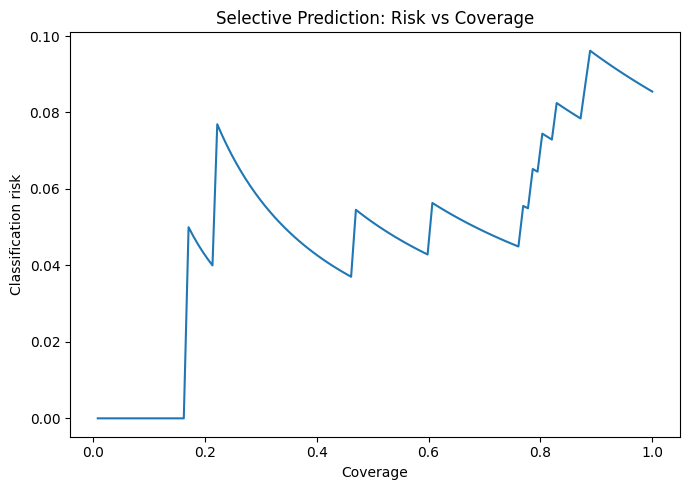

In [58]:
from sklearn.metrics import roc_auc_score

error_indicator = (
    uncertainty_test["probabilities"].argmax(axis=1)
    != uncertainty_test["labels"]
).astype(int)

entropy_scores = uncertainty_test["entropy"]

if len(np.unique(error_indicator)) == 2:

    error_detection_auc = roc_auc_score(
        error_indicator,
        entropy_scores
    )

    print(
        "Error detection AUROC:",
        round(error_detection_auc, 4)
    )
else:
    error_detection_auc = np.nan
    print("Error detection AUROC unavailable.")

def risk_coverage_curve(labels, probabilities, entropy):

    predictions = probabilities.argmax(axis=1)

    order = np.argsort(entropy)

    sorted_errors = (
        predictions[order] != labels[order]
    ).astype(float)

    coverage = np.arange(
        1, len(labels) + 1
    ) / len(labels)

    risk = np.cumsum(sorted_errors) / np.arange(
        1, len(labels) + 1
    )

    return coverage, risk


coverage, risk = risk_coverage_curve(
    uncertainty_test["labels"],
    uncertainty_test["probabilities"],
    uncertainty_test["entropy"]
)

plt.figure(figsize=(7, 5))
plt.plot(coverage, risk)
plt.xlabel("Coverage")
plt.ylabel("Classification risk")
plt.title("Selective Prediction: Risk vs Coverage")
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/E5_uncertainty/risk_coverage.png"
    ),
    dpi=300
)

plt.show()

accuracy            macro_f1           macro_auc          
               mean       std      mean       std      mean       std
noise_std                                                            
0.000      0.905983  0.000000  0.903596  0.000000  0.956972  0.000000
0.005      0.832479  0.004681  0.830104  0.005028  0.957484  0.001399
0.010      0.784615  0.007151  0.775592  0.004736  0.947466  0.004901
0.020      0.747009  0.021453  0.736572  0.019613  0.925128  0.011645
0.030      0.741880  0.035958  0.700161  0.041324  0.878444  0.014898
0.050      0.309402  0.022934  0.281585  0.023986  0.521445  0.013832

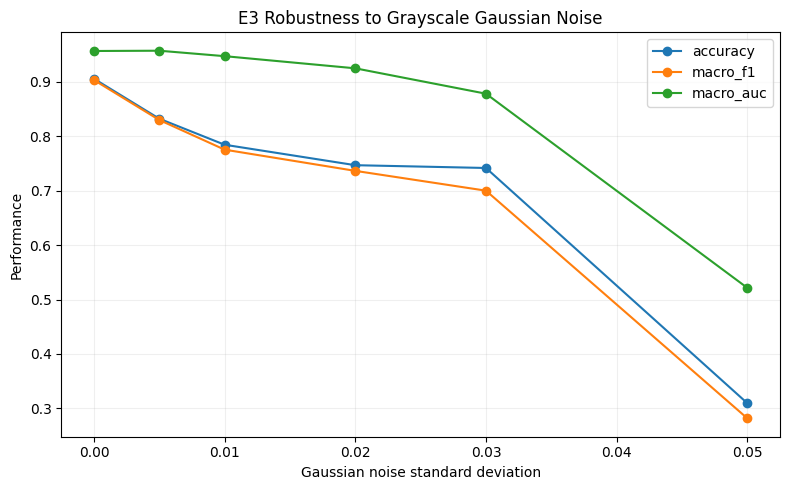

In [59]:
def evaluate_controlled_noise(
    model,
    loader,
    noise_levels=(0.0, 0.005, 0.01, 0.02, 0.03, 0.05),
    repetitions=5
):
    results = []

    model.eval()

    for repetition in range(repetitions):

        for noise_std in noise_levels:

            torch.manual_seed(100 + repetition)

            labels_all = []
            preds_all = []
            probs_all = []

            with torch.no_grad():

                for images, _, labels in loader:

                    images = images.to(DEVICE)

                    raw = denormalize_batch(images)

                    if noise_std > 0:

                        # One shared noise map per image
                        noise = torch.randn(
                            raw.size(0), 1,
                            raw.size(2), raw.size(3),
                            device=DEVICE
                        ) * noise_std

                        raw = (
                            raw + noise
                        ).clamp(0, 1)

                    inputs = normalize_batch(raw)

                    logits, _, _ = model(inputs)

                    probabilities = torch.softmax(
                        logits.float(), dim=1
                    )

                    labels_all.extend(labels.numpy())

                    preds_all.extend(
                        probabilities.argmax(1).cpu().numpy()
                    )

                    probs_all.extend(
                        probabilities.cpu().numpy()
                    )

            labels_all = np.asarray(labels_all)
            preds_all = np.asarray(preds_all)
            probs_all = np.asarray(probs_all)

            results.append({
                "repetition": repetition,
                "noise_std": noise_std,
                "accuracy": accuracy_score(
                    labels_all, preds_all
                ),
                "macro_f1": f1_score(
                    labels_all,
                    preds_all,
                    average="macro",
                    zero_division=0
                ),
                "macro_auc": roc_auc_score(
                    labels_all,
                    probs_all,
                    multi_class="ovr",
                    average="macro"
                )
            })

    return pd.DataFrame(results)


controlled_noise_df = evaluate_controlled_noise(
    model_e3,
    test_loader
)

display(
    controlled_noise_df.groupby("noise_std")[
        ["accuracy", "macro_f1", "macro_auc"]
    ].agg(["mean", "std"])
)


noise_summary = (
    controlled_noise_df.groupby("noise_std")
    [["accuracy", "macro_f1", "macro_auc"]]
    .mean()
)

plt.figure(figsize=(8, 5))

for metric in noise_summary.columns:
    plt.plot(
        noise_summary.index,
        noise_summary[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Gaussian noise standard deviation")
plt.ylabel("Performance")
plt.title("E3 Robustness to Grayscale Gaussian Noise")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    os.path.join(
        PROJECT_DIR,
        "results/E7_robustness/controlled_noise.png"
    ),
    dpi=300
)

plt.show()

In [60]:
def calculate_aurc(labels, probabilities, entropy):

    predictions = probabilities.argmax(axis=1)

    order = np.argsort(entropy)

    errors = (
        predictions[order] != labels[order]
    ).astype(float)

    coverage = np.arange(
        1, len(labels) + 1
    ) / len(labels)

    risk = np.cumsum(errors) / np.arange(
        1, len(labels) + 1
    )

    aurc = np.mean(risk)

    # Random selection reference
    total_errors = errors.sum()

    random_risk = (
        total_errors * np.arange(1, len(labels) + 1)
        / (len(labels) * np.arange(1, len(labels) + 1))
    )

    random_risk = np.full(
        len(labels),
        total_errors / len(labels)
    )

    random_aurc = random_risk.mean()

    return {
        "AURC": float(aurc),
        "Random AURC": float(random_aurc),
        "Coverage at 5% risk": float(
            coverage[np.where(risk <= 0.05)[0][-1]]
        ) if np.any(risk <= 0.05) else 0.0
    }


aurc_results = calculate_aurc(
    uncertainty_test["labels"],
    uncertainty_test["probabilities"],
    uncertainty_test["entropy"]
)

print(aurc_results)

{'AURC': 0.049690320178871074, 'Random AURC': 0.08547008547008546, 'Coverage at 5% risk': 0.7606837606837606}


In [61]:
import torch
import os

assert os.path.exists(E3_PATH), "E3 checkpoint not found!"

checkpoint = torch.load(
    E3_PATH,
    map_location="cpu",
    weights_only=False
)

# Adjust key list to match what was actually saved in 1kIPS0CpMjkA
required_keys = [
    "model_state_dict",
    "config",
    "epoch",
    "best_val_f1",
    "train_ids",
    "val_ids",
    "test_ids"
]

for key in required_keys:
    assert key in checkpoint, f"Missing field: {key}"

print("Checkpoint verification successful!")
print("Model:", checkpoint["config"]["architecture"])
print("Best epoch:", checkpoint["epoch"])
print("Best validation F1:", round(checkpoint["best_val_f1"], 4))
print(
    "File size:",
    round(os.path.getsize(E3_PATH) / (1024 ** 2), 2),
    "MB"
)

Checkpoint verification successful!
Model: MultiScaleBUSI
Best epoch: 8
Best validation F1: 0.8578
File size: 58.18 MB


# Comparison

In [62]:
E2_CHECKPOINT_PATH = (
    "/content/BUSI_Experiment_2/best_model_e2.pth"
)

if not os.path.exists(E2_CHECKPOINT_PATH):
    raise FileNotFoundError(
        "E2 checkpoint not found. Restore it from backup."
    )

checkpoint_e2 = torch.load(
    E2_CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

# model_e2 must be the same architecture used in E2 training.
model_e2.load_state_dict(
    checkpoint_e2["model_state_dict"]
)

model_e2.eval()

e2_metrics_final = run_epoch_e2(
    model_e2,
    test_loader
)

y_true_e2 = e2_metrics_final["labels"]
y_pred_e2 = e2_metrics_final["predictions"]
y_prob_e2 = e2_metrics_final["probabilities"]

print("E2 predictions recovered.")

E2 predictions recovered.


In [63]:
import os
import numpy as np

# Ensure Experiment 1 variables are defined
E1_PRED_PATH = "/content/BUSI_Experiment_1/test_predictions.npz"
if os.path.exists(E1_PRED_PATH):
    e1_data = np.load(E1_PRED_PATH)
    y_true_e1 = e1_data["y_true"]
    y_pred_e1 = e1_data["y_pred"]
    y_prob_e1 = e1_data["y_prob"]
else:
    # Fallback: Load the best model from Experiment 1 and generate predictions on the test loader
    E1_CHECKPOINT_PATH = "/content/BUSI_Experiment_1/best_model.pth"
    if os.path.exists(E1_CHECKPOINT_PATH):
        from torchvision import models
        import torch
        import torch.nn as nn

        baseline_weights = models.EfficientNet_B0_Weights.DEFAULT
        baseline_model = models.efficientnet_b0(weights=baseline_weights)
        in_features = baseline_model.classifier[1].in_features
        baseline_model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
        baseline_model = baseline_model.to(DEVICE)

        checkpoint_e1 = torch.load(E1_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
        baseline_model.load_state_dict(checkpoint_e1["model_state_dict"])
        baseline_model.eval()

        all_labels = []
        all_preds = []
        all_probs = []

        with torch.no_grad():
            for images, _, labels in test_loader:
                images = images.to(DEVICE)
                outputs = baseline_model(images)
                probs = torch.softmax(outputs, dim=1)
                preds = probs.argmax(dim=1)

                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(preds.cpu().numpy())
                all_probs.extend(probs.cpu().numpy())

        y_true_e1 = np.array(all_labels)
        y_pred_e1 = np.array(all_preds)
        y_prob_e1 = np.array(all_probs)

        os.makedirs(os.path.dirname(E1_PRED_PATH), exist_ok=True)
        np.savez_compressed(E1_PRED_PATH, y_true=y_true_e1, y_pred=y_pred_e1, y_prob=y_prob_e1)
    else:
        raise FileNotFoundError("Experiment 1 test predictions or checkpoint not found.")

# Perform alignment checks
assert len(y_true_e1) == len(test_df)
assert len(y_true_e2) == len(test_df)
assert len(y_true_e3) == len(test_df)

assert np.array_equal(y_true_e1, y_true_e3)
assert np.array_equal(y_true_e2, y_true_e3)

print("Test sample counts:", len(test_df))
print("E1/E2/E3 test labels are aligned.")

Test sample counts: 117
E1/E2/E3 test labels are aligned.


In [64]:
def stratified_bootstrap(
    y_true,
    y_pred,
    y_prob,
    n_bootstrap=2000,
    seed=42
):

    rng = np.random.default_rng(seed)

    class_indices = [
        np.where(y_true == c)[0]
        for c in range(NUM_CLASSES)
    ]

    f1_scores = []
    auc_scores = []
    accuracy_scores = []

    for _ in range(n_bootstrap):

        indices = np.concatenate([
            rng.choice(
                group,
                size=len(group),
                replace=True
            )
            for group in class_indices
        ])

        yt = y_true[indices]
        yp = y_pred[indices]
        probabilities = y_prob[indices]

        f1_scores.append(
            f1_score(
                yt,
                yp,
                average="macro",
                zero_division=0
            )
        )

        accuracy_scores.append(
            accuracy_score(yt, yp)
        )

        auc_scores.append(
            roc_auc_score(
                yt,
                probabilities,
                multi_class="ovr",
                average="macro"
            )
        )

    def interval(values):
        return (
            float(np.percentile(values, 2.5)),
            float(np.percentile(values, 97.5))
        )

    return {
        "macro_f1": {
            "mean": float(np.mean(f1_scores)),
            "ci_lower": interval(f1_scores)[0],
            "ci_upper": interval(f1_scores)[1]
        },
        "accuracy": {
            "mean": float(np.mean(accuracy_scores)),
            "ci_lower": interval(accuracy_scores)[0],
            "ci_upper": interval(accuracy_scores)[1]
        },
        "macro_auc": {
            "mean": float(np.mean(auc_scores)),
            "ci_lower": interval(auc_scores)[0],
            "ci_upper": interval(auc_scores)[1]
        }
    }


model_predictions = {
    "E1": (y_true_e1, y_pred_e1, y_prob_e1),
    "E2": (y_true_e2, y_pred_e2, y_prob_e2),
    "E3": (y_true_e3, y_pred_e3, y_prob_e3)
}

bootstrap_results = {}

for name, (yt, yp, prob) in model_predictions.items():

    bootstrap_results[name] = stratified_bootstrap(
        yt,
        yp,
        prob
    )

print(json.dumps(bootstrap_results, indent=2))

{
  "E1": {
    "macro_f1": {
      "mean": 0.893060121452351,
      "ci_lower": 0.8310619708160691,
      "ci_upper": 0.943594787183166
    },
    "accuracy": {
      "mean": 0.8981794871794875,
      "ci_lower": 0.8376068376068376,
      "ci_upper": 0.9487179487179487
    },
    "macro_auc": {
      "mean": 0.9658051092565533,
      "ci_lower": 0.9263129417588637,
      "ci_upper": 0.993544998197945
    }
  },
  "E2": {
    "macro_f1": {
      "mean": 0.8994238185730413,
      "ci_lower": 0.8452599927020922,
      "ci_upper": 0.9506038930581614
    },
    "accuracy": {
      "mean": 0.8976196581196584,
      "ci_lower": 0.8376068376068376,
      "ci_upper": 0.9487179487179487
    },
    "macro_auc": {
      "mean": 0.9693162593868663,
      "ci_lower": 0.9336937904878697,
      "ci_upper": 0.9969034475377855
    }
  },
  "E3": {
    "macro_f1": {
      "mean": 0.8965165437167043,
      "ci_lower": 0.8381180415196455,
      "ci_upper": 0.947254174344935
    },
    "accuracy": {
      

In [65]:
E1_PRED_PATH = (
    "/content/BUSI_Experiment_1/test_predictions.npz"
)

if os.path.exists(E1_PRED_PATH):
    e1_data = np.load(E1_PRED_PATH)
    y_true_e1 = e1_data["y_true"]
    y_pred_e1 = e1_data["y_pred"]
    y_prob_e1 = e1_data["y_prob"]
    print("E1 predictions loaded from file.")
else:
    print("E1 predictions file not found. Re-generating baseline predictions from best baseline checkpoint...")
    # Fallback: Load the best model from Experiment 1 and generate predictions on the test loader
    E1_CHECKPOINT_PATH = "/content/BUSI_Experiment_1/best_model.pth"
    if os.path.exists(E1_CHECKPOINT_PATH):
        # Instantiate baseline model structure
        from torchvision import models
        import torch.nn as nn

        baseline_weights = models.EfficientNet_B0_Weights.DEFAULT
        baseline_model = models.efficientnet_b0(weights=baseline_weights)
        in_features = baseline_model.classifier[1].in_features
        baseline_model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
        baseline_model = baseline_model.to(DEVICE)

        # Load checkpoint weights
        checkpoint_e1 = torch.load(E1_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
        baseline_model.load_state_dict(checkpoint_e1["model_state_dict"])
        baseline_model.eval()

        # Generate predictions
        all_labels = []
        all_preds = []
        all_probs = []

        with torch.no_grad():
            for images, _, labels in test_loader:
                images = images.to(DEVICE)
                outputs = baseline_model(images)
                probs = torch.softmax(outputs, dim=1)
                preds = probs.argmax(dim=1)

                all_labels.extend(labels.cpu().numpy())
                all_preds.extend(preds.cpu().numpy())
                all_probs.extend(probs.cpu().numpy())

        y_true_e1 = np.array(all_labels)
        y_pred_e1 = np.array(all_preds)
        y_prob_e1 = np.array(all_probs)

        # Cache them so we don't have to do this again
        os.makedirs(os.path.dirname(E1_PRED_PATH), exist_ok=True)
        np.savez_compressed(E1_PRED_PATH, y_true=y_true_e1, y_pred=y_pred_e1, y_prob=y_prob_e1)
        print("E1 predictions successfully re-generated and saved.")
    else:
        raise FileNotFoundError(
            f"Neither the predictions file ({E1_PRED_PATH}) nor the model checkpoint ({E1_CHECKPOINT_PATH}) was found. "
            "Please ensure Experiment 1 has been run and its outputs are saved."
        )

E1 predictions loaded from file.


In [66]:
def paired_bootstrap_f1(
    y_true,
    pred_a,
    pred_b,
    n_bootstrap=2000,
    seed=42
):

    rng = np.random.default_rng(seed)

    class_indices = [
        np.where(y_true == c)[0]
        for c in range(NUM_CLASSES)
    ]

    differences = []

    for _ in range(n_bootstrap):

        indices = np.concatenate([
            rng.choice(
                group,
                size=len(group),
                replace=True
            )
            for group in class_indices
        ])

        score_a = f1_score(
            y_true[indices],
            pred_a[indices],
            average="macro",
            zero_division=0
        )

        score_b = f1_score(
            y_true[indices],
            pred_b[indices],
            average="macro",
            zero_division=0
        )

        differences.append(score_b - score_a)

    differences = np.array(differences)

    return {
        "mean_difference": float(differences.mean()),
        "ci_lower": float(np.percentile(differences, 2.5)),
        "ci_upper": float(np.percentile(differences, 97.5)),
        "bootstrap_probability_positive": float(
            np.mean(differences > 0)
        )
    }


paired_results = {
    "E1_vs_E2": paired_bootstrap_f1(
        y_true_e1, y_pred_e1, y_pred_e2
    ),
    "E1_vs_E3": paired_bootstrap_f1(
        y_true_e1, y_pred_e1, y_pred_e3
    ),
    "E2_vs_E3": paired_bootstrap_f1(
        y_true_e3, y_pred_e2, y_pred_e3
    )
}

print(json.dumps(paired_results, indent=2))

{
  "E1_vs_E2": {
    "mean_difference": 0.006363697120690264,
    "ci_lower": -0.04397160519787799,
    "ci_upper": 0.061307956173980833,
    "bootstrap_probability_positive": 0.584
  },
  "E1_vs_E3": {
    "mean_difference": 0.00345642226435319,
    "ci_lower": -0.051152105188624605,
    "ci_upper": 0.05795569082775005,
    "bootstrap_probability_positive": 0.5465
  },
  "E2_vs_E3": {
    "mean_difference": -0.0029072748563370742,
    "ci_lower": -0.056492540470902686,
    "ci_upper": 0.05063596682307096,
    "bootstrap_probability_positive": 0.4625
  }
}


In [67]:
comparison_rows = []

for name, (yt, yp, prob) in model_predictions.items():

    report = classification_report(
        yt,
        yp,
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )

    ci = bootstrap_results[name]

    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(yt, yp),
        "Macro F1": f1_score(
            yt, yp, average="macro"
        ),
        "Macro AUROC": roc_auc_score(
            yt,
            prob,
            multi_class="ovr",
            average="macro"
        ),
        "Accuracy CI": (
            f"{ci['accuracy']['ci_lower']:.3f}–"
            f"{ci['accuracy']['ci_upper']:.3f}"
        ),
        "Macro F1 CI": (
            f"{ci['macro_f1']['ci_lower']:.3f}–"
            f"{ci['macro_f1']['ci_upper']:.3f}"
        ),
        "Macro AUROC CI": (
            f"{ci['macro_auc']['ci_lower']:.3f}–"
            f"{ci['macro_auc']['ci_upper']:.3f}"
        ),
        "Malignant Recall": report["malignant"]["recall"],
        "Malignant F1": report["malignant"]["f1-score"]
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

comparison_df.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results/E8_statistics/final_model_comparison.csv"
    ),
    index=False
)

,Model,Accuracy,Macro F1,Macro AUROC,Accuracy CI,Macro F1 CI,Macro AUROC CI,Malignant Recall,Malignant F1
0,E1,0.897436,0.892202,0.964955,0.838–0.949,0.831–0.944,0.926–0.994,0.935484,0.892308
1,E2,0.897436,0.898844,0.968571,0.838–0.949,0.845–0.951,0.934–0.997,0.903226,0.861538
2,E3,0.897436,0.896126,0.957024,0.846–0.949,0.838–0.947,0.917–0.989,0.838710,0.852459


In [68]:
def calculate_classwise_metrics(y_true, y_pred):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    rows = []

    total = cm.sum()

    for i, name in enumerate(CLASSES):

        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp

        rows.append({
            "Class": name,
            "Sensitivity": tp / (tp + fn + 1e-8),
            "Specificity": tn / (tn + fp + 1e-8),
            "Precision": tp / (tp + fp + 1e-8)
        })

    return pd.DataFrame(rows)


for name, (yt, yp, _) in model_predictions.items():

    print("\n", name)
    display(calculate_classwise_metrics(yt, yp))


 E1


,Class,Sensitivity,Specificity,Precision
0,benign,0.878788,0.921569,0.935484
1,malignant,0.935484,0.941860,0.852941
2,normal,0.900000,0.969072,0.857143



 E2


,Class,Sensitivity,Specificity,Precision
0,benign,0.863636,0.941176,0.950000
1,malignant,0.903226,0.930233,0.823529
2,normal,1.000000,0.969072,0.869565



 E3


,Class,Sensitivity,Specificity,Precision
0,benign,0.909091,0.882353,0.909091
1,malignant,0.838710,0.953488,0.866667
2,normal,0.950000,0.979381,0.904762


In [69]:
import os
import zipfile
from google.colab import files

folders = [
    "BUSI_Experiment_1",
    "BUSI_Experiment_2",
    "BUSI_Reliable_AI"
]

zip_path = "/content/BUSI_All_Experiments.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in folders:
        for root, dirs, filenames in os.walk(f"/content/{folder}"):
            for filename in filenames:
                filepath = os.path.join(root, filename)
                arcname = os.path.relpath(filepath, "/content")
                zf.write(filepath, arcname)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>